#Customer Campaign Response Prediction | Machine Learning

## Project Overview

A retail superstore is preparing a year-end promotional campaign for its Gold Membership program. The membership is offered at a discounted price of $499 compared with its regular price of 999 and provides customers with a 20% discount on purchases.

Rather than targeting every customer equally, the business wants to identify customers most likely to respond positively to the campaign. A more targeted approach could improve marketing efficiency, reduce unnecessary outreach and increase membership conversions.

## Business Objective

Develop and evaluate machine learning classification models to predict whether an existing customer will accept the Gold Membership offer, using demographic information, purchase behavior and historical campaign engagement.

## Analytical Approach

1. **Exploratory Data Analysis:** Examine customer demographics, spending patterns and campaign response behavior.
2. **Data Preparation:** Address missing values, prepare categorical variables and engineer relevant customer features.
3. **Predictive Modeling:** Train and compare classification algorithms to identify likely campaign responders.
4. **Model Evaluation:** Evaluate precision, recall, F1-score and the trade-offs relevant to marketing decisions.
5. **Business Recommendations:** Translate model findings into practical customer-targeting strategies.

## Tools & Technologies

**Python | Pandas | NumPy | Matplotlib | Seaborn | Scikit-learn | Imbalanced-learn**

---

*This project uses a customer marketing dataset for analytical and educational purposes. Model predictions and recommendations are illustrative and have not been deployed in a live marketing campaign.*
  
  

### **Importing the necessary libraries**

In [15]:
import pandas as pd
import requests
from io import StringIO
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

#algorithms to use
from sklearn.tree import DecisionTreeClassifier, plot_tree

# Metrics to evaluate the model
from sklearn import metrics
from sklearn.metrics import confusion_matrix, classification_report, precision_recall_curve,recall_score
from sklearn import tree
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression


# for tuning the model
from sklearn.model_selection import GridSearchCV
from imblearn.over_sampling import SMOTE

# KFold
import numpy as np
from sklearn.model_selection import KFold
from sklearn.metrics import accuracy_score


from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import accuracy_score, mean_squared_error

from sklearn.neighbors import KNeighborsClassifier

#to ignore warnings
import warnings
warnings.filterwarnings("ignore")

#**Data Overview**
Let’s take a first look at the structure of the dataset and understand what kinds of data we’re working with.

In [16]:
orig_url="https://drive.google.com/file/d/1GS4kOWVTCKcexmFJE9eLwCudIAtg7Gqa/view?usp=drive_link" # share link to data set

file_id = orig_url.split('/')[-2]
dwn_url='https://drive.google.com/uc?export=download&id=' + file_id
url = requests.get(dwn_url).text

csv_raw = StringIO(url)
df = pd.read_csv(csv_raw)

In [17]:
df.head()

,Id,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Response,Complain
0,1826,1970,Graduation,Divorced,84835.0,0,0,6/16/2014,0,189,...,111,189,218,1,4,4,6,1,1,0
1,1,1961,Graduation,Single,57091.0,0,0,6/15/2014,0,464,...,7,0,37,1,7,3,7,5,1,0
2,10476,1958,Graduation,Married,67267.0,0,1,5/13/2014,0,134,...,15,2,30,1,3,2,5,2,0,0
3,1386,1967,Graduation,Together,32474.0,1,1,11/5/2014,0,10,...,0,0,0,1,1,0,2,7,0,0
4,5371,1989,Graduation,Single,21474.0,1,0,8/4/2014,0,6,...,11,0,34,2,3,1,2,7,1,0


In [18]:
df.shape

(2240, 22)

In [19]:
df.head(10)

,Id,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Response,Complain
0,1826,1970,Graduation,Divorced,84835.0,0,0,6/16/2014,0,189,...,111,189,218,1,4,4,6,1,1,0
1,1,1961,Graduation,Single,57091.0,0,0,6/15/2014,0,464,...,7,0,37,1,7,3,7,5,1,0
2,10476,1958,Graduation,Married,67267.0,0,1,5/13/2014,0,134,...,15,2,30,1,3,2,5,2,0,0
3,1386,1967,Graduation,Together,32474.0,1,1,11/5/2014,0,10,...,0,0,0,1,1,0,2,7,0,0
4,5371,1989,Graduation,Single,21474.0,1,0,8/4/2014,0,6,...,11,0,34,2,3,1,2,7,1,0
5,7348,1958,PhD,Single,71691.0,0,0,3/17/2014,0,336,...,240,32,43,1,4,7,5,2,1,0
6,4073,1954,2n Cycle,Married,63564.0,0,0,1/29/2014,0,769,...,15,34,65,1,10,10,7,6,1,0
7,1991,1967,Graduation,Together,44931.0,0,1,1/18/2014,0,78,...,0,0,7,1,2,1,3,5,0,0
8,4047,1954,PhD,Married,65324.0,0,1,11/1/2014,0,384,...,21,32,5,3,6,2,9,4,0,0
9,9477,1954,PhD,Married,65324.0,0,1,11/1/2014,0,384,...,21,32,5,3,6,2,9,4,0,0


In [20]:
df.columns

Index(['Id', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome',
       'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits',
       'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts',
       'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases',
       'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth',
       'Response', 'Complain'],
      dtype='object')

In [21]:
df.dtypes

,0
Id,int64
Year_Birth,int64
Education,object
Marital_Status,object
Income,float64
Kidhome,int64
Teenhome,int64
Dt_Customer,object
Recency,int64
MntWines,int64


In [22]:
df['Response'].value_counts()

,count
Response,
0,1906
1,334


#Initial Observations:
- The dataset contains **2,240 rows** and **22 columns**.
- Target variable: `Response` (binary — 1 = Yes, 0 = No).
- Several categorical variables need to be encoded (like `Education`, `Marital_Status`).
- Some numerical variables (like `Income`) may have outliers or missing values.


#**Statistical Summary of Each Variable**
We use `df.describe().T` to get insights into the **central tendency**, **spread**, and **range** of numerical variables in the dataset.

This helps us:
- Identify **skewed distributions**
- Flag potential **outliers**
- Understand the scale and units of each feature

In [23]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Id,2240.0,5592.159821,3246.662198,0.0,2828.25,5458.5,8427.75,11191.0
Year_Birth,2240.0,1968.805804,11.984069,1893.0,1959.00,1970.0,1977.00,1996.0
Income,2216.0,52247.251354,25173.076661,1730.0,35303.00,51381.5,68522.00,666666.0
Kidhome,2240.0,0.444196,0.538398,0.0,0.00,0.0,1.00,2.0
Teenhome,2240.0,0.506250,0.544538,0.0,0.00,0.0,1.00,2.0
Recency,2240.0,49.109375,28.962453,0.0,24.00,49.0,74.00,99.0
MntWines,2240.0,303.935714,336.597393,0.0,23.75,173.5,504.25,1493.0
MntFruits,2240.0,26.302232,39.773434,0.0,1.00,8.0,33.00,199.0
MntMeatProducts,2240.0,166.950000,225.715373,0.0,16.00,67.0,232.00,1725.0
MntFishProducts,2240.0,37.525446,54.628979,0.0,3.00,12.0,50.00,259.0


#Observations:

- Income: The average income is around 52.000 with a wide range from **1,730** to  **$666,666**.

- Recency: The average number of days since the last purchase is around 49 days.

- **Spending** is highest on:
  - **Wines**: Mean of ~303
  - **Meat Products**: Mean of ~166

- The `Response` column confirms **class imbalance**, with a small percentage of positive responses


#**Unique Values for Each Variable**
We also check the number of unique values in each column to understand the diversity of the data.

In [24]:
# checking unique values in each column
df.nunique()

,0
Id,2240
Year_Birth,59
Education,5
Marital_Status,8
Income,1974
Kidhome,3
Teenhome,3
Dt_Customer,663
Recency,100
MntWines,776


#Observations:

- `Education` and `Marital_Status` have relatively few unique values.
- `Id` has as many unique values as rows, not useful for modeling, so we’ll drop it.
- `Year_Birth` and `Income` have a **wide range of values** these are continuous and may need outlier treatment.
- `Response` has only **2 unique values (0 and 1)**
- `Dt_Customer` is a datetime feature,→ We’ll extract the year to simplify it.



### **Dropping the Id Column**
 The `Id` column is a unique identifier and doesn’t contribute predictive value — we’ll remove it.

In [25]:
df.drop(columns=['Id'], inplace=True)

#Checking for Missing/Null Values
We check for missing values in each column to prepare for data cleaning.

In [26]:
df.isna().sum()

,0
Year_Birth,0
Education,0
Marital_Status,0
Income,24
Kidhome,0
Teenhome,0
Dt_Customer,0
Recency,0
MntWines,0
MntFruits,0


#Observations:

- Only the **`Income`** column has missing values (**24 records**).
- All other columns are complete.


#**Handling Missing Values in the Income Column:**  
We’ll fill missing Income values using the mean income of the dataset, as this is a reasonable default that avoids data loss while maintaining scale.

In [27]:
mean_income = df['Income'].mean()
df['Income'] = df['Income'].fillna(mean_income)

Text(0, 0.5, 'Count')

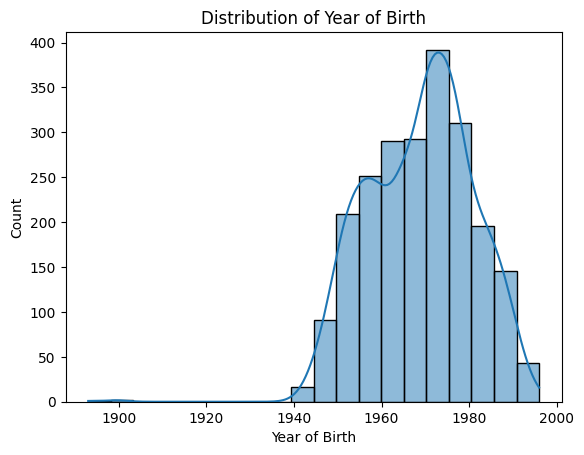

In [28]:
# Subplot 1: Year of Birth distribution
sns.histplot(df["Year_Birth"], bins=20, kde=True)
plt.title("Distribution of Year of Birth")
plt.xlabel("Year of Birth")
plt.ylabel("Count")

# **Visualizing Key Categorical Variables**
We create bar charts for variables to better understand the distribution of Education, Marital Status and Year of Registration.

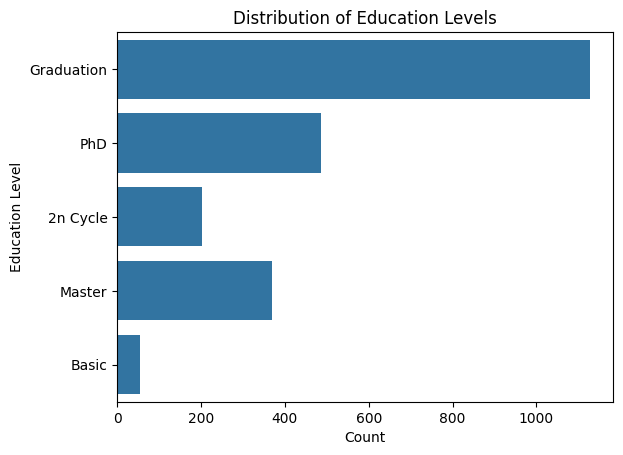

In [29]:
# Bar chart for Education level distribution
sns.countplot(y=df["Education"])
plt.title("Distribution of Education Levels")
plt.xlabel("Count")
plt.ylabel("Education Level")
plt.show()

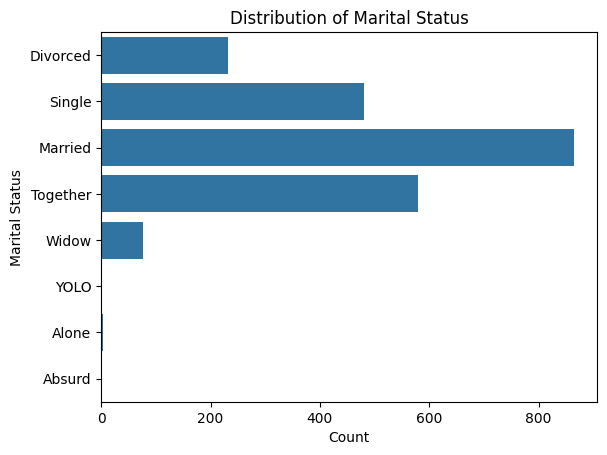

In [30]:
# Bar chart for Marital Status distribution
sns.countplot(y=df["Marital_Status"])
plt.title("Distribution of Marital Status")
plt.xlabel("Count")
plt.ylabel("Marital Status")
plt.show()

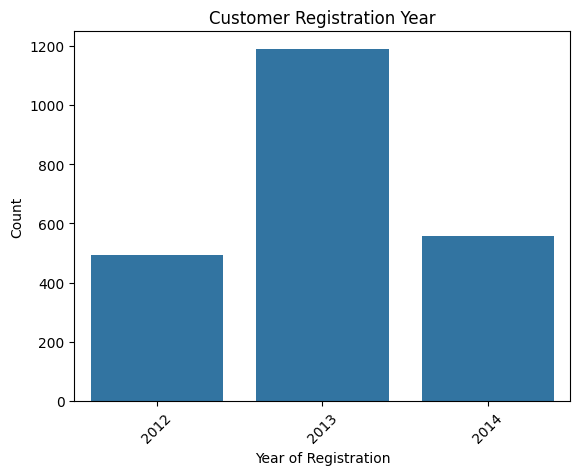

In [31]:
# Plot for Customer Registration Year
df["Dt_Customer"] = pd.to_datetime(df["Dt_Customer"])
df["Dt_Customer_Year"] = df["Dt_Customer"].dt.year
sns.countplot(x=df["Dt_Customer_Year"])
plt.title("Customer Registration Year")
plt.xlabel("Year of Registration")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.show()

#**Observations:**
- **Education:** Most customers are **Graduates**, followed by **PhDs** and **Masters** — indicating a well-educated customer base.
- **Marital Status:** Majority are **Married** or **Single**, but there are outlier labels like “YOLO”, “Absurd”, and “Alone” that we’ll normalize in the next step.
- **Registration Year:** A clear spike in new customers between **2012 and 2014**, with a peak in **2013**.

# Converting Categorical values to numerical values - Education
The `Education` column contains **ordinal categorical values** (i.e., they follow a meaningful order of increasing qualification).

To prepare this for modeling, we map the education levels to numerical values as follows:

- `Basic` - 1  
- `Graduation` - 2  
- `2n Cycle` - 3  
- `Master` - 4  
- `PhD` - 5

This preserves the relative rank of education levels while making the data model-friendly.

In [32]:
# Display unique values in the 'Education' column before transformation
df['Education'].unique()

array(['Graduation', 'PhD', '2n Cycle', 'Master', 'Basic'], dtype=object)

In [33]:
# Map ordinal categorical values (education levels) to numerical values
# Since 'Basic' < 'Graduation' < '2n Cycle' < 'Master' < 'PhD', we assign increasing numeric values
education_dict = {'Basic':1, 'Graduation':2, '2n Cycle':3, 'Master':4, "PhD":5}
df['Education']= df['Education'].replace(education_dict)

#Converting Categorical values to numerical values - Marital Status

The `Marital_Status` column includes a wide range of values, including realistic statuses (`Single`, `Married`) and quirky outliers (`YOLO`, `Absurd`, `Alone`).

To reduce noise and focus on meaningful categories, we group them as:

- `Married` - 2  
- All others - 1 (assumed not married)

This transformation helps simplify the variable while retaining its predictive value.

In [34]:
# Display unique values in the 'Marital_Status' column before transformation
df['Marital_Status'].unique()


array(['Divorced', 'Single', 'Married', 'Together', 'Widow', 'YOLO',
       'Alone', 'Absurd'], dtype=object)

In [35]:
# Convert marital status into unmarried(1) and married(2)
mapping = {
    'Married': 2,
    'Together': 1,
    'Single': 1,
    'Divorced': 1,
    'Widow': 1,
    'YOLO': 1,
    'Alone': 1,
    'Absurd': 1
}

# Apply mapping using .replace()
df['Marital_Status'] = df['Marital_Status'].replace(mapping)

# Check unique values after transformation
print(df['Marital_Status'].unique())

[1 2]


In [36]:
df.head()

,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,...,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Response,Complain,Dt_Customer_Year
0,1970,2,1,84835.0,0,0,2014-06-16,0,189,104,...,189,218,1,4,4,6,1,1,0,2014
1,1961,2,1,57091.0,0,0,2014-06-15,0,464,5,...,0,37,1,7,3,7,5,1,0,2014
2,1958,2,2,67267.0,0,1,2014-05-13,0,134,11,...,2,30,1,3,2,5,2,0,0,2014
3,1967,2,1,32474.0,1,1,2014-11-05,0,10,0,...,0,0,1,1,0,2,7,0,0,2014
4,1989,2,1,21474.0,1,0,2014-08-04,0,6,16,...,0,34,2,3,1,2,7,1,0,2014


All values are now binary:
- **2** for married
- **1** for everyone else

This reduces noise from outlier categories and keeps the feature interpretable for models.

# Combining Kidhome & Teenhome Columns
The dataset contains two separate columns:
- `Kidhome`: Number of children in the household
- `Teenhome`: Number of teenagers in the household

Since both represent **children living at home**, we combine them into a single feature called **`NoofKids`**.

In [37]:
df['NoofKids']=df['Kidhome']+df['Teenhome']
df.drop(columns=['Kidhome', 'Teenhome'], inplace=True)

#Creating Total Spending Feature – Total_Products
The dataset includes separate columns for spending on different products.
To capture a customer's **overall engagement with the store**, we create a new feature called **`Total_Products`**, which is the **sum of all product-related spendings**.

In [38]:
# Display the column names in the dataset
df.columns

Index(['Year_Birth', 'Education', 'Marital_Status', 'Income', 'Dt_Customer',
       'Recency', 'MntWines', 'MntFruits', 'MntMeatProducts',
       'MntFishProducts', 'MntSweetProducts', 'MntGoldProds',
       'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases',
       'NumStorePurchases', 'NumWebVisitsMonth', 'Response', 'Complain',
       'Dt_Customer_Year', 'NoofKids'],
      dtype='object')

In [39]:
# Create a new feature 'Total_Products' by summing up all product-related columns
df['Total_Products']= df['MntWines'] + df['MntFruits'] + df['MntMeatProducts'] + df['MntFishProducts'] + df['MntSweetProducts'] + df['MntGoldProds']
df.drop(columns=['MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds'], inplace=True)

In [40]:
df.columns

Index(['Year_Birth', 'Education', 'Marital_Status', 'Income', 'Dt_Customer',
       'Recency', 'NumDealsPurchases', 'NumWebPurchases',
       'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth',
       'Response', 'Complain', 'Dt_Customer_Year', 'NoofKids',
       'Total_Products'],
      dtype='object')

#Categorizing Features for Analysis

To organize our analysis, we separate the dataset into:

- `num_cols`: Continuous numerical variables
- `cat_cols`: Categorical or identifier variables

In [41]:
# Creating numerical columns
num_cols=['Income','Recency','Total_Products', 'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth','NoofKids', 'Education','Marital_Status' ]

# Creating categorical variables
cat_cols= ['Year_Birth', 'Dt_Customer', 'Response', 'Complain','Dt_Customer_Year']

###Visualizing Distributions of Numerical Features


array([[<Axes: title={'center': 'Income'}>,
        <Axes: title={'center': 'Recency'}>,
        <Axes: title={'center': 'Total_Products'}>],
       [<Axes: title={'center': 'NumDealsPurchases'}>,
        <Axes: title={'center': 'NumWebPurchases'}>,
        <Axes: title={'center': 'NumCatalogPurchases'}>],
       [<Axes: title={'center': 'NumStorePurchases'}>,
        <Axes: title={'center': 'NumWebVisitsMonth'}>,
        <Axes: title={'center': 'NoofKids'}>],
       [<Axes: title={'center': 'Education'}>,
        <Axes: title={'center': 'Marital_Status'}>, <Axes: >]],
      dtype=object)

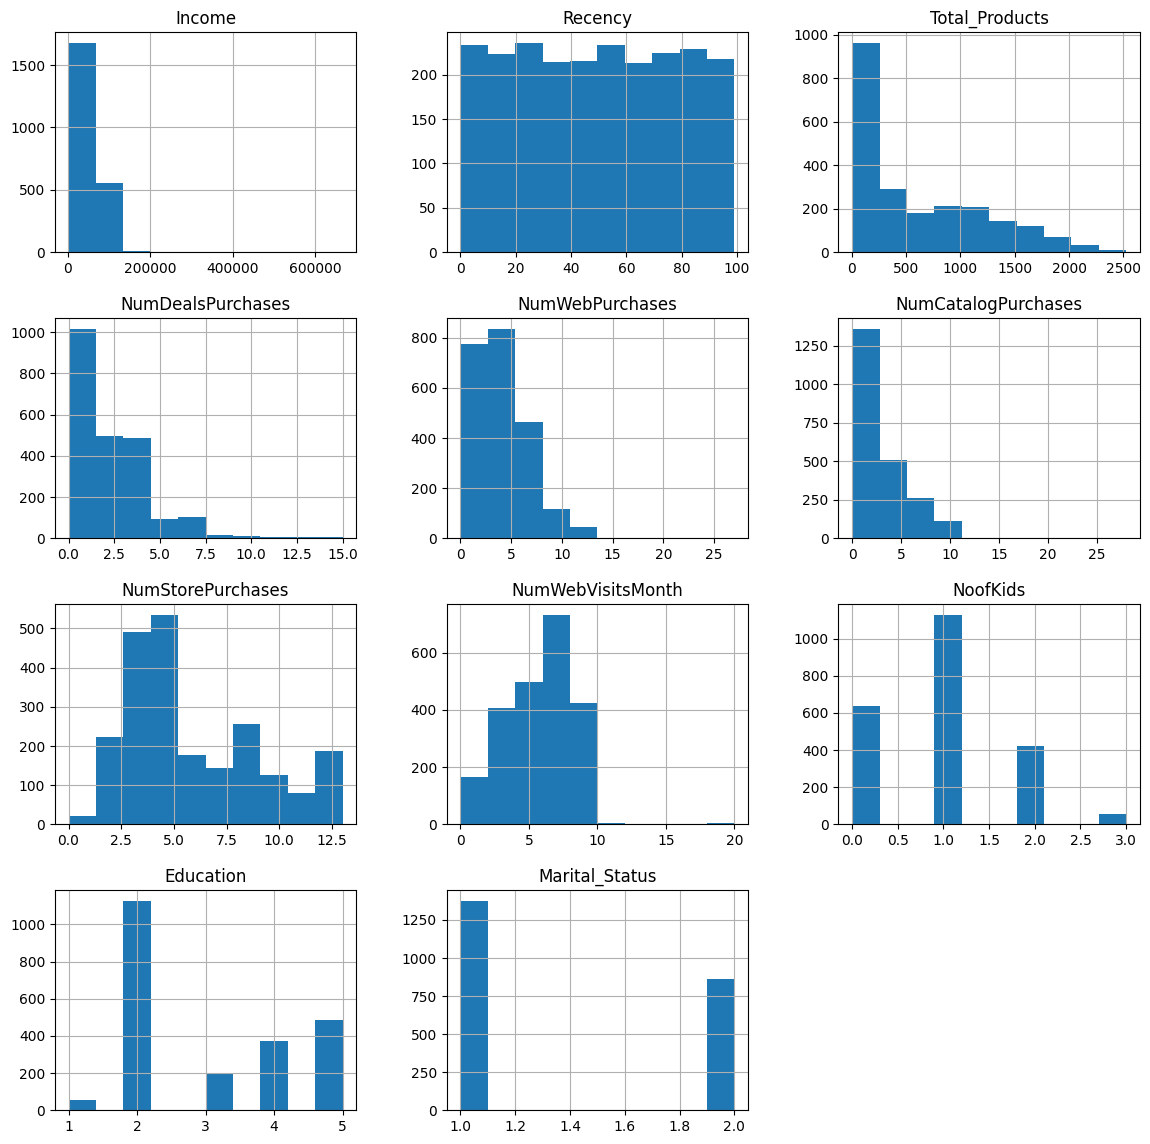

In [42]:
df[num_cols].hist(figsize=(14,14))

In [ ]:
#Mean of numerical varibles grouped by response
df.groupby(['Response'])[num_cols].mean()

,Income,Recency,Total_Products,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,NoofKids,Education,Marital_Status
Response,,,,,,,,,,,
0,50856.124754,51.514690,538.929171,2.323190,3.911857,2.391920,5.736621,5.320567,1.003673,3.002099,1.401889
1,60185.836082,35.383234,987.392216,2.335329,5.071856,4.203593,6.095808,5.293413,0.646707,3.308383,1.293413


#Feature Distributions by Response


We now examine how key categorical features (Education, Marital Status, and Number of Kids) relate to campaign response.

Stacked bar plots allow us to see:
- Response distribution within each group
- Potential early indicators of high vs. low responder groups

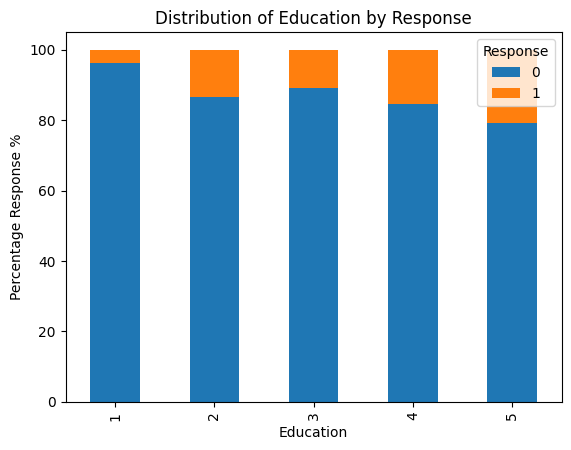

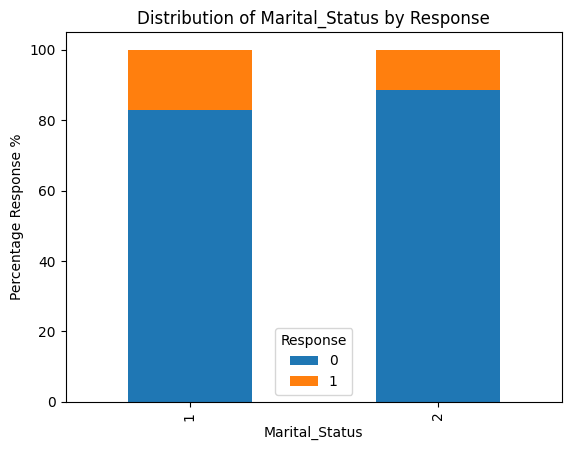

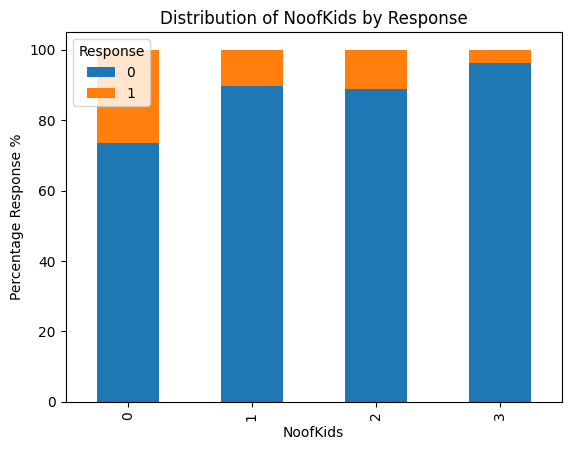

In [43]:
#Checking how response is related to categorical variables
cat_columns = ['Education', 'Marital_Status', 'NoofKids']

for i in cat_columns:
    if i!= 'Response':
      (pd.crosstab(df[i], df['Response'], normalize='index')*100).plot(kind='bar', stacked=True)
      plt.title(f'Distribution of {i} by Response')
      plt.xlabel(i)
      plt.ylabel('Percentage Response %')
      plt.show()

#Observations:

- Higher education levels (PhD, Masters) tend to show slightly higher response rates.
- Married customers seem slightly more responsive than singles/divorced.
- Customers with **0–1 kids** respond better than those with more kids.

These patterns suggest customer segmentation based on education and family status may improve campaign targeting.


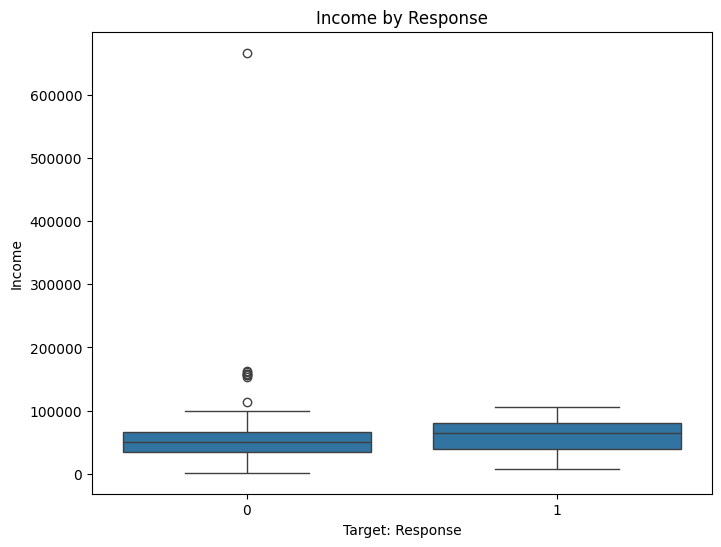

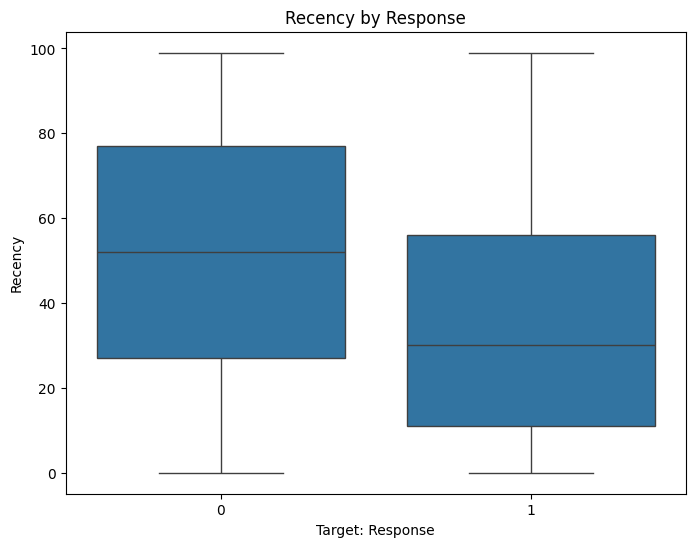

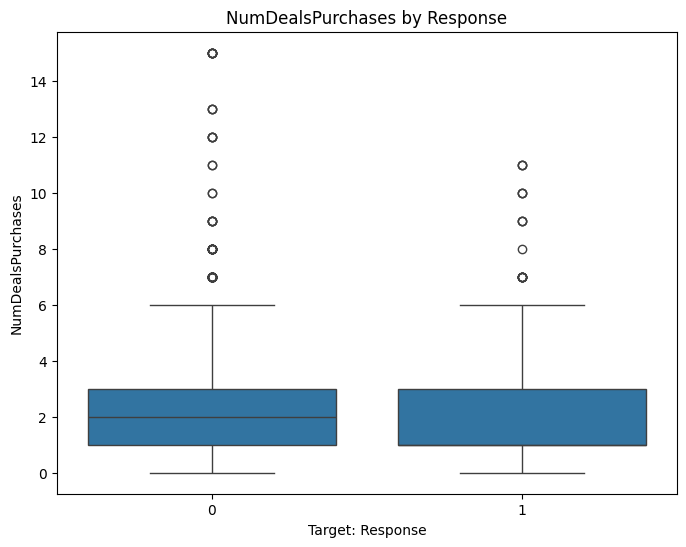

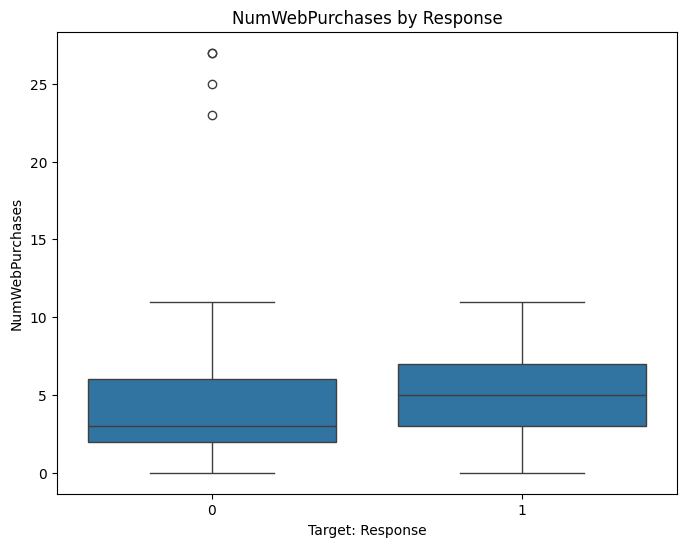

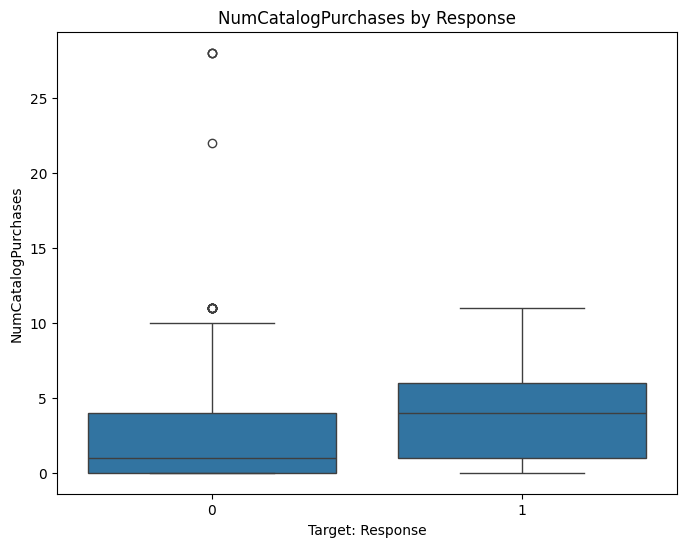

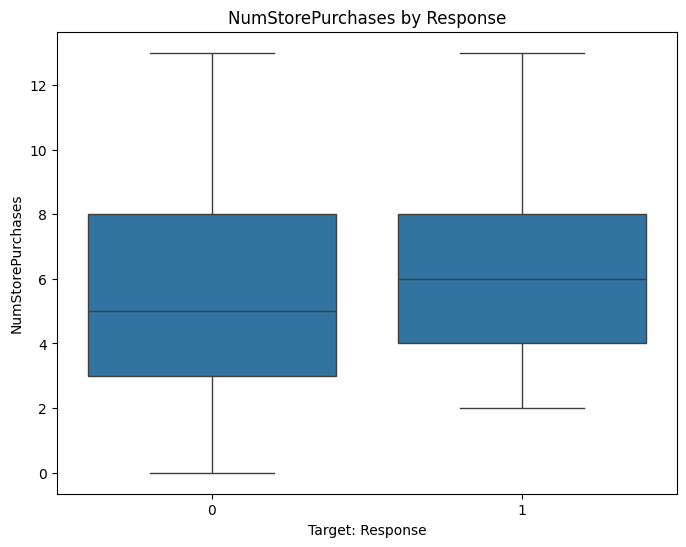

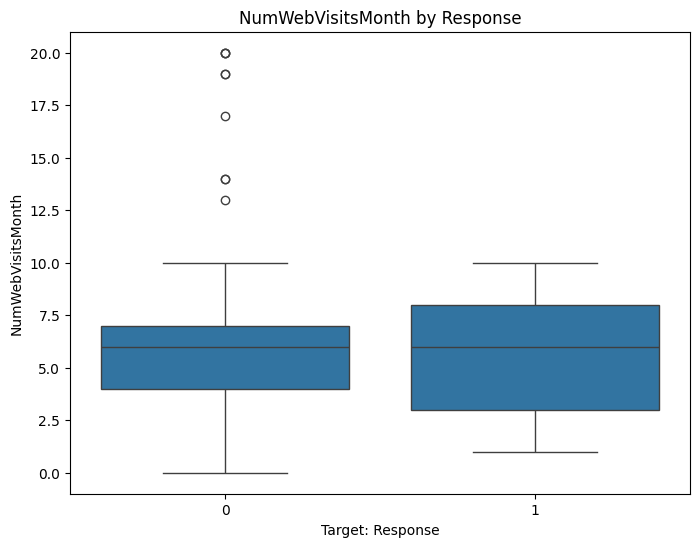

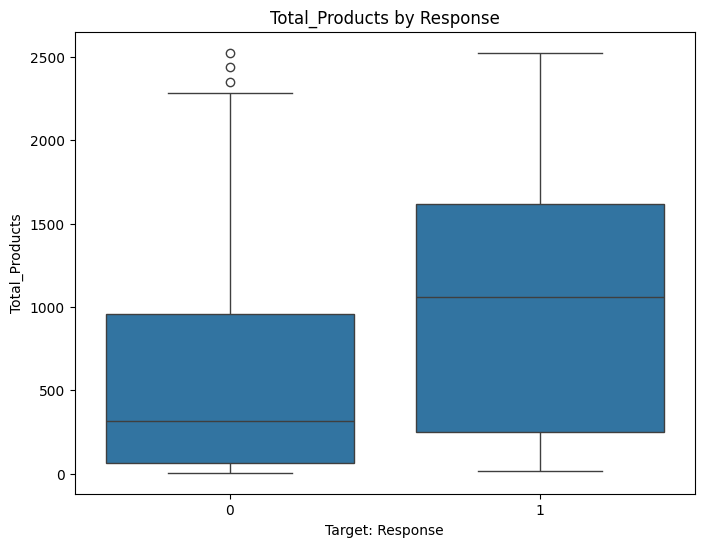

In [44]:
# List of feature variables for y-axis
features = ['Income','Recency', 'NumDealsPurchases', 'NumWebPurchases','NumCatalogPurchases',
            'NumStorePurchases', 'NumWebVisitsMonth','Total_Products']

# Create boxplots using a for loop
for feature in features:
    plt.figure(figsize=(8, 6))
    sns.boxplot(x='Response', y=feature, data=df)
    plt.xlabel('Target: Response')
    plt.ylabel(feature)
    plt.title(f'{feature} by Response')
    plt.show()

#Key Observations from Boxplots:

- **Income:** Responders tend to have higher income on average.
- **Total_Products:** Responders purchase more — higher overall spending.
- **NumCatalogPurchases & NumStorePurchases:** Responders engage more in traditional shopping methods.
- **NumWebVisitsMonth:** Interestingly, responders tend to visit the website **less frequently** — possibly indicating impulsive or targeted shoppers vs. browsers.
- **Recency:** Customers who responded did so relatively **recently**.


These patterns suggest that a combination of **income, spending behavior**, and **shopping recency** could be strong predictors of campaign response.


#Outlier Detection and Removal
Extreme values can:
- Skew model performance
- Distort feature distributions
- Mislead interpretation

We use the **IQR (Interquartile Range) method** to identify and remove outliers from key numeric columns like `Income`, `Total_Products`, and various purchase behaviors.


In [45]:
def remove_outliers(df, column):
    # Calculate the first and third quartiles
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    # Calculate the IQR
    IQR = Q3 - Q1

    # Define the bounds for outliers
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Remove rows where the column value is outside the bounds
    df_cleaned = df[(df[column] >= lower_bound) & (df[column] <= upper_bound)]

    return df_cleaned

df = remove_outliers(df, 'Income')
df = remove_outliers(df, 'Total_Products')
df = remove_outliers(df, 'NumDealsPurchases')
df = remove_outliers(df, 'NumWebPurchases')
df = remove_outliers(df, 'NumCatalogPurchases')
df = remove_outliers(df, 'NumWebVisitsMonth')

In [46]:
df.shape

(2119, 16)

In [47]:
df.columns

Index(['Year_Birth', 'Education', 'Marital_Status', 'Income', 'Dt_Customer',
       'Recency', 'NumDealsPurchases', 'NumWebPurchases',
       'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth',
       'Response', 'Complain', 'Dt_Customer_Year', 'NoofKids',
       'Total_Products'],
      dtype='object')

# **Correlation Matrix**
We examine the correlation matrix to identify relationships between numerical predictor variables.

We’ll visualize this using a heatmap to quickly detect strong positive or negative associations between variables.

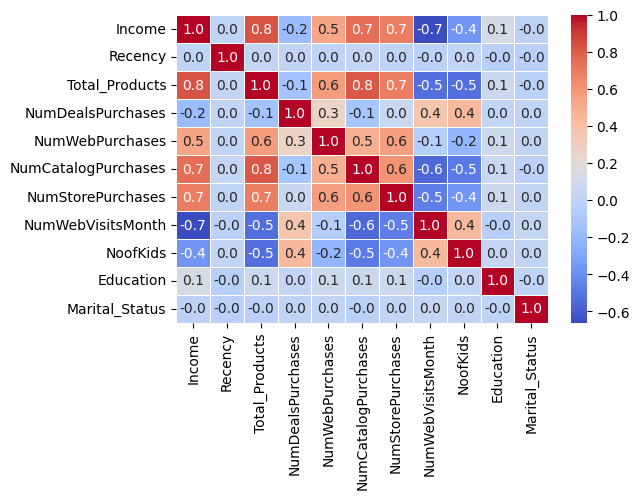

In [48]:
# Calculate the correlation matrix
corr_matrix = df[num_cols].corr()

# Set larger figure size for better readability
plt.figure(figsize=(6, 4))  # Adjust width and height as needed

# Create the heatmap with annotations
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".1f", linewidths=0.5)

# Show the heatmap
plt.show()

#Key Insights from Correlation Matrix:

####Positive Correlations:
- **Income** is highly correlated with:
  - `Total_Products`
  - `NumCatalogPurchases`
- **Total_Products** is also strongly linked to:
  - `NumStorePurchases`
  - `NumCatalogPurchases`

**Interpretation:** Higher income customers tend to spend more across all channels.

#### Negative Correlations:
- **NumWebVisitsMonth** has a negative correlation with:
  - `Total_Products`
  - `NumCatalogPurchases`

**Interpretation:** Customers who **browse more online** tend to **buy less** — possibly just window shoppers.




#Highly Correlated Feature Pairs

In [49]:
# Find correlation pairs above 0.6 (excluding self-correlations of 1.0)
threshold = 0.7
high_corr_pairs = corr_matrix.unstack().sort_values(ascending=False)

# Filter out self-correlations and keep only values > 0.7
high_corr_pairs = high_corr_pairs[(high_corr_pairs < 1.0) & (high_corr_pairs > threshold)]

# Convert to DataFrame for better readability
high_corr_df = high_corr_pairs.reset_index()
high_corr_df.columns = ['Feature 1', 'Feature 2', 'Correlation']

# Display the result
display(high_corr_df.drop_duplicates(subset=['Correlation']))


,Feature 1,Feature 2,Correlation
0,Income,Total_Products,0.829530
2,Total_Products,NumCatalogPurchases,0.815562
4,NumCatalogPurchases,Income,0.742620


Even though these features are strongly related, they each tell us something different.

1. `Income` shows how much money someone makes.
2. `Total_Products` shows how many products they bought.
3. `NumCatalogPurchases` shows how many times they bought from a catalog.


They are connected, but not the same thing. And if we drop them just because they are related, we might lose important information that could help our model make better predictions.



#Scatterplots and Pairplot Analysis

We use scatterplots and a **pairplot** to visualize how numerical features interact with each other.

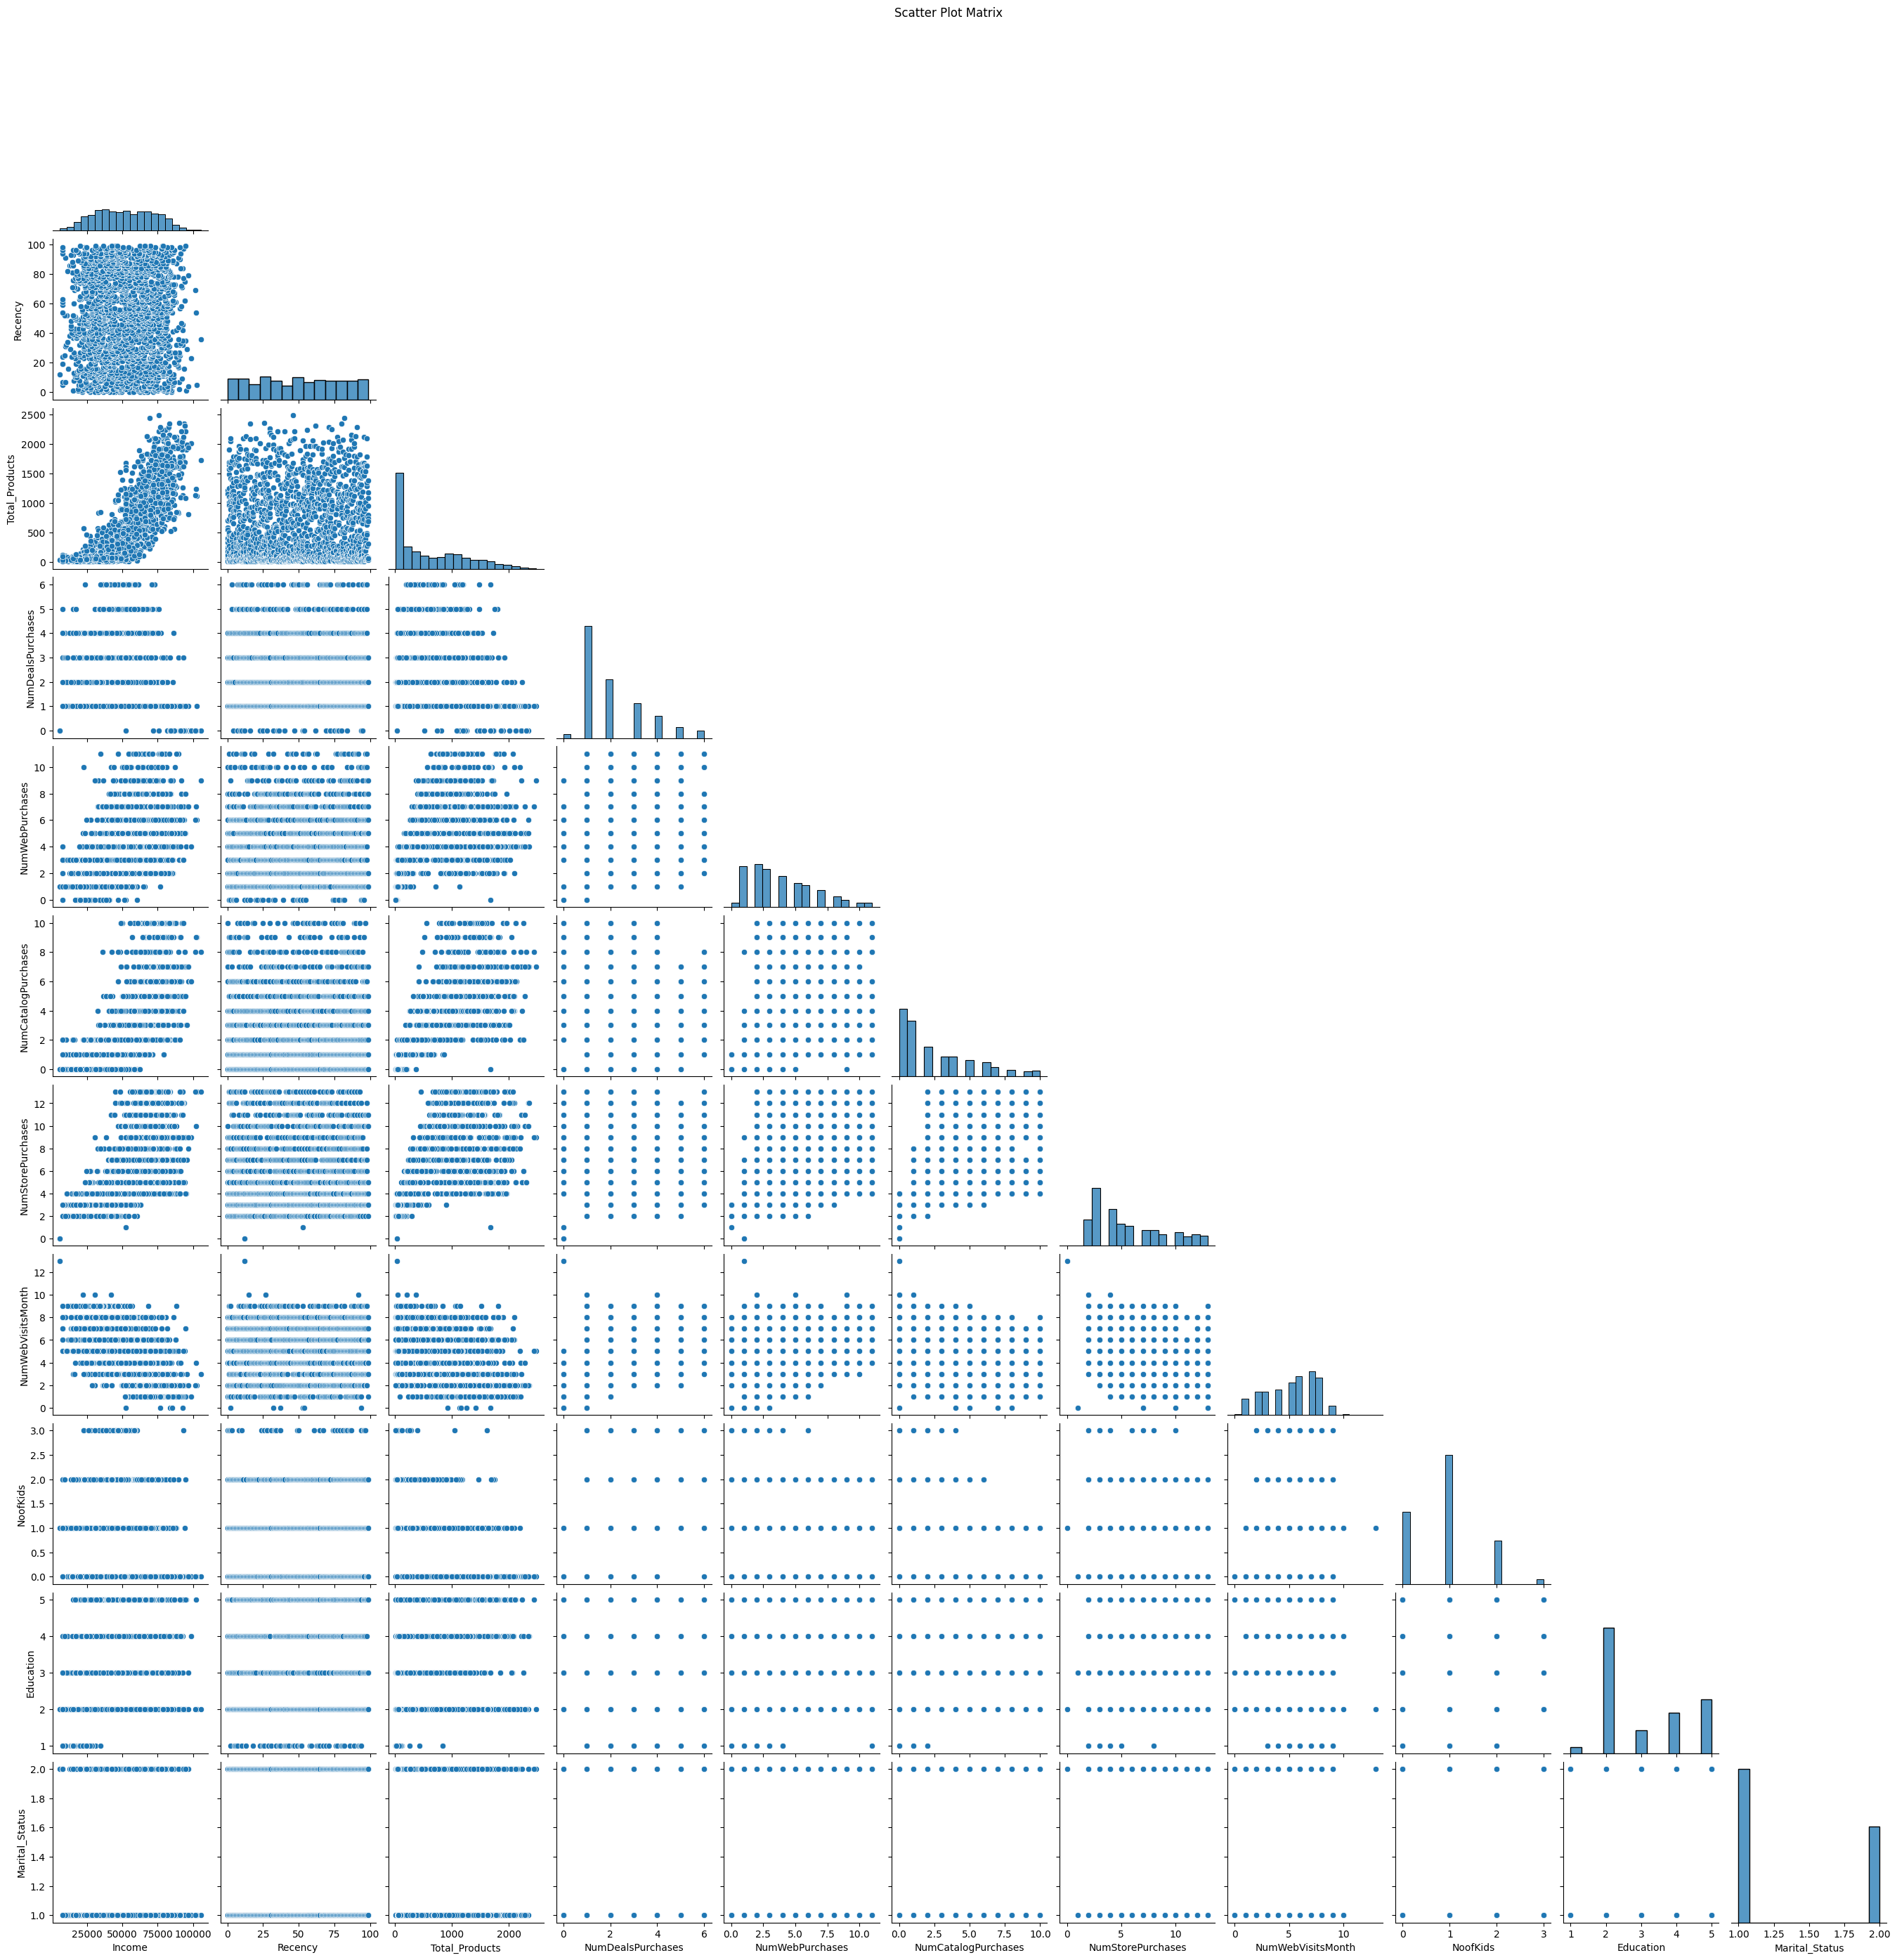

In [50]:
# Plot the scatter plot matrix
sns.pairplot(df[num_cols], height=2.5, corner=True)
plt.suptitle("Scatter Plot Matrix", y=1.02)
plt.show()

#Observations from Scatterplots:

1. **Income vs. Spending:** Customers with higher income tend to spend more, but with diminishing returns at very high incomes.
  
2. **NumCatalogPurchases vs. Total_Products:** Strong clustering pattern, with higher catalog purchasers also buying more overall.

3. **Year_Birth vs. Income:** A few young customers (<1990) have very high incomes — likely outliers.

4. **NumWebVisitsMonth:** Outliers exist with extremely high web visits but low spending — possibly non-converting traffic.

5. **Clustered Behavior:** Many features form **distinct groupings**, hinting at **customer segmentation** potential.

6. **Discrete Features:** Features like `NoofKids`, `NumDealsPurchases` show stripe-like patterns — expected from discrete variables.

> These visuals reinforce patterns we saw earlier and will guide our modeling and feature selection strategy.


#Preparing Data for Modeling

##Separating Features and Target

We drop irrelevant or identifier columns like:
- `Dt_Customer` and `Dt_Customer_Year` (temporal metadata)
- `Year_Birth` (already indirectly captured in other behaviors)

In [51]:
features=df.drop(['Response', 'Dt_Customer', 'Year_Birth', 'Dt_Customer_Year'], axis=1)

target=df['Response']

#Feature Scaling with StandardScaler

Since our dataset includes variables with different scales (e.g., `Income`, `NoofKids`, `Recency`), we use **StandardScaler** to normalize all features.

In [52]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(features)
X_scaled = pd.DataFrame(X_scaled, columns=features.columns)

#Train-Test Split

We split the data:
- **70% for training**
- **30% for testing**
- Using `stratify=target` to preserve the class imbalance ratio in both sets

In [53]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X_scaled, target, test_size=0.3, random_state=1, stratify=target)

In [54]:
X_train.head()

,Education,Marital_Status,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,NoofKids,Total_Products
1126,-0.816503,-0.792147,0.255418,0.098580,-0.796071,1.165682,0.166096,-0.548096,-0.554832,-0.097613,-1.264913,0.705796
221,-0.816503,-0.792147,-0.099619,-1.382922,-0.061689,1.165682,-0.582748,-0.239865,1.199273,-0.097613,0.104010,-0.381745
15,-0.816503,1.262393,0.162516,-1.693004,1.407074,-0.765577,-0.582748,-0.239865,-0.554832,-0.097613,1.472932,-0.698876
1048,-0.816503,1.262393,-1.577671,-0.004780,-0.061689,-1.151829,-0.957170,-0.856327,0.760747,-0.097613,0.104010,-0.911403
1482,-0.816503,-0.792147,0.632389,0.718744,1.407074,0.393178,0.166096,1.917753,-0.554832,-0.097613,0.104010,0.348817


In [ ]:
y_train.head()

,Response
1189,0
232,0
16,1
1104,0
1572,0


In [55]:
# creating metric function
def metrics_score(actual, predicted):
    print(classification_report(actual, predicted))
    cm = confusion_matrix(actual, predicted)
    plt.figure(figsize=(8,5))
    sns.heatmap(cm, annot=True,  fmt='.2f', xticklabels=['No Response', 'Responded'], yticklabels=['No Response', 'Responded'])
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.show()

#Addressing Class Imbalance with SMOTE

In [57]:
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)

In [58]:
#Check the shapes before and after SMOTE
print("Original training set shape:", X_train.shape, y_train.shape)
print("Resampled training set shape:", X_train_resampled.shape, y_train_resampled.shape)
print("Test set shape (unchanged):", X_test.shape, y_test.shape)

Original training set shape: (1483, 12) (1483,)
Resampled training set shape: (2536, 12) (2536,)
Test set shape (unchanged): (636, 12) (636,)


The resampled dataset now has equal representation of both classes, which gives our models a fair chance to learn from responders.

# Logistic Regression

In [59]:
lg = LogisticRegression()
lg.fit(X_train, y_train)

LogisticRegression()

              precision    recall  f1-score   support

           0       0.89      0.97      0.93      1268
           1       0.62      0.29      0.39       215

    accuracy                           0.87      1483
   macro avg       0.75      0.63      0.66      1483
weighted avg       0.85      0.87      0.85      1483



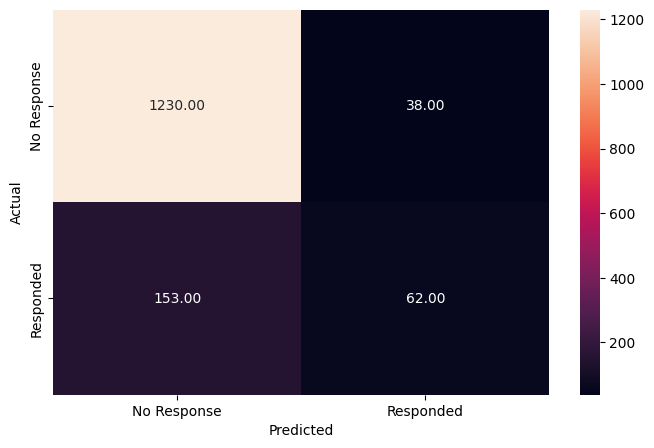

In [60]:
y_pred_train = lg.predict(X_train)
metrics_score(y_train, y_pred_train)

# Observations
1. Out of 215 people who actually responded to our campaign, we only caught 62. That means we missed over 70% of our potential customers — which is a major loss in terms of opportunity and revenue.
2. Recall for responders (class 1) is just 29%, showing that the model struggles to detect the group we care about most, leaving room for applying techniques to to fix data imbalance.
3. The model shows 87% accuracy, but that's mostly because it’s doing great with the "No Response" group. That’s not our goal. In marketing, identifying responders is what drives ROI — and that’s where the model is underperforming.
4. Right now, our model is conservative — it's avoiding false alarms, but in doing so, it’s also ignoring the people most likely to convert. We should consider strategies like threshold tuning or better features to improve recall, even at the cost of some precision.

              precision    recall  f1-score   support

           0       0.89      0.97      0.93       544
           1       0.61      0.27      0.38        92

    accuracy                           0.87       636
   macro avg       0.75      0.62      0.65       636
weighted avg       0.85      0.87      0.85       636



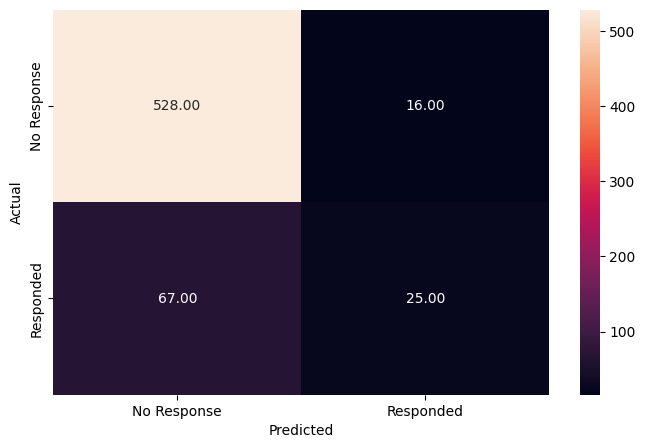

In [61]:
# checking the performance on the test dataset
y_pred_test_lg = lg.predict(X_test)
metrics_score(y_test, y_pred_test_lg)

# Observations
1. Out of 92 customers who actually responded, we only caught 25. That’s a recall of 27%, meaning we’re failing to identify 7 out of 10 potential leads — and leaving revenue on the table.
2. With a strong recall of 97% for non-responders, the model is good at avoiding false alarms. But from a business perspective, this hurts us — because missing actual responders is more costly than wrongly contacting a few uninterested ones.
3.  Just like in training, the model performs well overall (87% accuracy), but that’s only because the data is imbalanced. It again struggles with recall for responders, showing a need to rethink our model strategy if we care about capturing more conversions.
4. Since the business goal is to increase campaign success, we should tweak the model (e.g. lower decision threshold, try ensemble models, engineer more relevant features) to boost recall, even if precision takes a small hit.

## SMOTE data - Logistic Regression

In [62]:
lg.fit(X_train_resampled, y_train_resampled)

LogisticRegression()

              precision    recall  f1-score   support

           0       0.80      0.79      0.80      1268
           1       0.79      0.81      0.80      1268

    accuracy                           0.80      2536
   macro avg       0.80      0.80      0.80      2536
weighted avg       0.80      0.80      0.80      2536



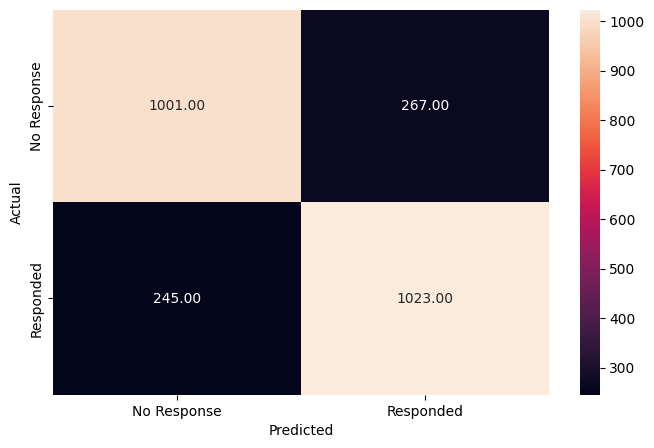

In [63]:
y_pred_train = lg.predict(X_train_resampled)
metrics_score(y_train_resampled, y_pred_train)

# Observations
1. The recall for responders significantly improved to 81% after using SMOTE, meaning the model now captures a large portion of customers likely to respond, which is a critical win for maximizing campaign effectiveness.
2. Precision dropped slightly, indicating that the model is now also predicting many uninterested customers as responders. This trade-off could lead to higher campaign costs due to increased call volume, but the gain in conversions may justify the expense.
3. The confusion matrix shows 267 false positives (predicted responders who won’t respond), which emphasizes the need to balance between reach and efficiency. For a low-cost, high-return offer like gold membership, this is likely an acceptable compromise.
4. The model performs almost equally across both classes (precision, recall ~80%), which is uncommon in imbalanced datasets—highlighting that SMOTE helped logistic regression generalize better across both responder and non-responder groups.

              precision    recall  f1-score   support

           0       0.94      0.78      0.85       544
           1       0.34      0.68      0.46        92

    accuracy                           0.76       636
   macro avg       0.64      0.73      0.65       636
weighted avg       0.85      0.76      0.79       636



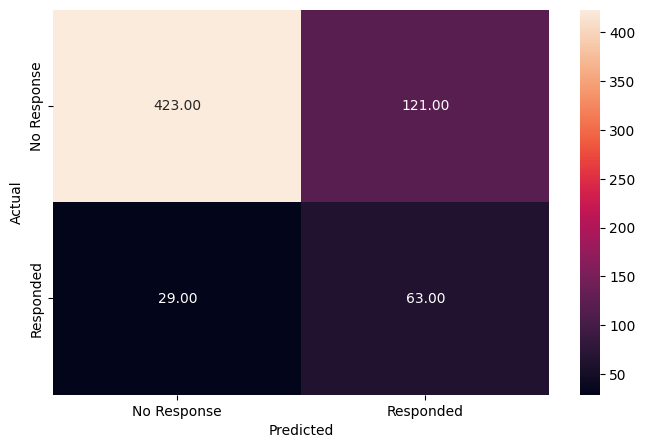

In [64]:
y_pred_test_lg = lg.predict(X_test)
metrics_score(y_test, y_pred_test_lg)

# Observations
1. The recall for responders (class 1) has significantly improved to 68%, capturing 63 out of 92 actual responders. This is a notable increase in campaign effectiveness, allowing the store to focus efforts on more likely buyers.
2. This improved recall comes at the cost of precision for responders (only 34%), meaning many predicted positives will not actually convert. From a business standpoint, this could still be acceptable if the cost of calling is low and the profit margin from conversions is high.
3. The model correctly avoids most false negatives (only 29 responders missed), which reduces missed revenue opportunities — crucial for a limited-time high-value offer like the gold membership.
4. On the downside, the model misclassifies 121 non-responders as potential responders, increasing operational load. This highlights a trade-off between recall and marketing cost efficiency.
5. Overall accuracy is 76%, but the real win here is in targeting — the improved recall for responders suggests this model could better support aggressive campaign strategies aimed at revenue maximization.

Fold 1 Accuracy: 0.8941176470588236
Fold 2 Accuracy: 0.8588235294117647
Fold 3 Accuracy: 0.9058823529411765
Fold 4 Accuracy: 0.8705882352941177
Fold 5 Accuracy: 0.8352941176470589
Fold 6 Accuracy: 0.8823529411764706
Fold 7 Accuracy: 0.8823529411764706
Fold 8 Accuracy: 0.8705882352941177
Fold 9 Accuracy: 0.9176470588235294
Fold 10 Accuracy: 0.8705882352941177
Fold 11 Accuracy: 0.8941176470588236
Fold 12 Accuracy: 0.8235294117647058
Fold 13 Accuracy: 0.8588235294117647
Fold 14 Accuracy: 0.8705882352941177
Fold 15 Accuracy: 0.7529411764705882
Fold 16 Accuracy: 0.8588235294117647
Fold 17 Accuracy: 0.8588235294117647
Fold 18 Accuracy: 0.8941176470588236
Fold 19 Accuracy: 0.8352941176470589
Fold 20 Accuracy: 0.8690476190476191
Fold 21 Accuracy: 0.8571428571428571
Fold 22 Accuracy: 0.9047619047619048
Fold 23 Accuracy: 0.8809523809523809
Fold 24 Accuracy: 0.9285714285714286 -- Maximum
Fold 25 Accuracy: 0.8809523809523809


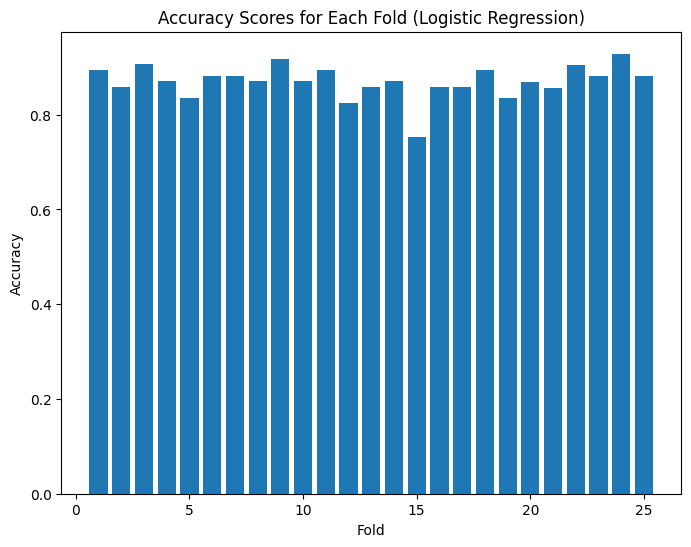

In [65]:
# Number of folds for cross-validation
n_splits = 25

# Create a KFold object
kf = KFold(n_splits=n_splits, shuffle=True, random_state=42)

# Initialize an empty list to store the accuracy scores for each fold
fold_accuracies = []

# Iterate through the folds
for train_index, test_index in kf.split(X_scaled):

    # Split the data into training and testing sets for the current fold
    X_train_fold, X_test_fold = X_scaled.iloc[train_index], X_scaled.iloc[test_index]
    y_train_fold, y_test_fold = target.iloc[train_index], target.iloc[test_index]

    # Create and train the Logistic Regression model
    model = LogisticRegression(random_state=42)
    model.fit(X_train_fold, y_train_fold)

    # Make predictions on the test set for the current fold
    y_pred_fold = model.predict(X_test_fold)

    # Calculate accuracy for the current fold
    fold_accuracy = accuracy_score(y_test_fold, y_pred_fold)
    fold_accuracies.append(fold_accuracy)

# Calculate the average accuracy across all folds
max_accuracy = np.max(fold_accuracies)

for i in range(1, n_splits + 1):
    if max_accuracy == fold_accuracies[i-1]:
        print(f"Fold {i} Accuracy: {fold_accuracies[i-1]} -- Maximum")
    else:
      print(f"Fold {i} Accuracy: {fold_accuracies[i-1]}")

# Create a bar chart to show the accuracies across the different folds
plt.figure(figsize=(8, 6))
plt.bar(range(1, n_splits + 1), fold_accuracies)
plt.xlabel("Fold")
plt.ylabel("Accuracy")
plt.title("Accuracy Scores for Each Fold (Logistic Regression)")
plt.show()

# Observations
1. Most folds had accuracy between 85%–89%, showing consistency — which is good. But we should remember: high accuracy doesn't mean we're catching the right customers (responders), especially with imbalanced data.
2. Fold 24 achieved the highest score (92.86%), which is promising. But again, since we're prioritizing recall for responders, accuracy might not reflect how well we’re identifying potential buyers.
3. One fold dropped to 75% accuracy (Fold 15), suggesting that the model might occasionally misperform depending on the sample — something to keep in mind when scaling to new data or unseen customer segments.
4. While this cross-validation confirms decent stability in accuracy, we should now run cross-validated recall analysis for class 1 (responders) to evaluate if the model is actually helping our business target the right people.

# Decision Tree


In [66]:
# building decision tree
dt = DecisionTreeClassifier(max_leaf_nodes=20, random_state=42)
# fitting decision tree
dt.fit(X_train, y_train)

DecisionTreeClassifier(max_leaf_nodes=20, random_state=42)

Create a column of predictions using the testing data

In [67]:
y_pred = dt.predict(X_test)
y_pred[:6]

array([0, 1, 0, 0, 0, 0])

Check the performance on the training data

              precision    recall  f1-score   support

           0       0.92      0.97      0.94      1268
           1       0.74      0.51      0.60       215

    accuracy                           0.90      1483
   macro avg       0.83      0.74      0.77      1483
weighted avg       0.89      0.90      0.90      1483



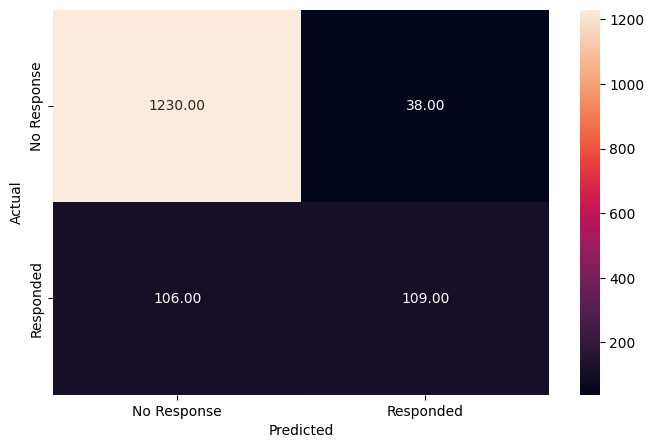

In [68]:
#checking performance on train dataset
y_train_pred_dt=dt.predict(X_train)
metrics_score(y_train,y_train_pred_dt)

# Observations
1. The decision tree correctly identified 51% of responders on the training set and 109 out of 215 responders overall. This directly improves how well we can target and convert potential customers.
2. While precision is a bit lower (0.74 for responders), that's a reasonable trade if our goal is to maximize reach to potential buyers. More hits mean more chances to drive revenue through personalized campaigns.
3. With over 100 responders correctly identified, we can now design more focused, data-backed campaigns. This reduces the chance of missing out on people who were actually interested.
4. On top of performance, decision trees are easy to explain to business teams. We can clearly show what factors led to predictions — which is useful when marketing wants to understand why someone is likely to respond.

Check the performance on the testing data

              precision    recall  f1-score   support

           0       0.89      0.94      0.92       544
           1       0.49      0.32      0.38        92

    accuracy                           0.85       636
   macro avg       0.69      0.63      0.65       636
weighted avg       0.83      0.85      0.84       636



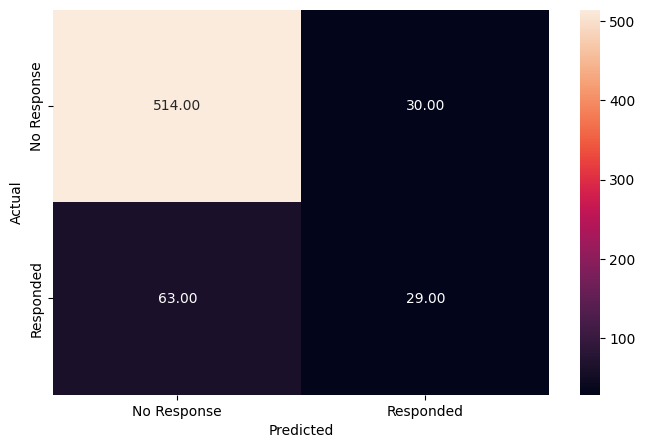

In [69]:
#checking model performace of dt
y_pred_test_dt = dt.predict(X_test)
metrics_score(y_test, y_pred_test_dt)

# Observations
1. The model catches 32% of the actual responders but still missing 2 out of every 3 potential buyers.
2. Out of 92 people who actually responded, 63 were missed. This means marketing campaigns may continue to miss a significant portion of our interested audience.
3. The model predicts more people as responders (even some incorrectly), which is fine if our business can afford a bit of outreach spillover in return for finding more true leads.
4. Compared to logistic regression, decision trees show more promise for detecting responders. To really make this count, we should now explore boosted trees (like Random Forest) for smarter splits and better recall.


# SMOTE data - Decision Tree

In [70]:
dt.fit(X_train_resampled, y_train_resampled)

DecisionTreeClassifier(max_leaf_nodes=20, random_state=42)

              precision    recall  f1-score   support

           0       0.88      0.86      0.87      1268
           1       0.86      0.88      0.87      1268

    accuracy                           0.87      2536
   macro avg       0.87      0.87      0.87      2536
weighted avg       0.87      0.87      0.87      2536



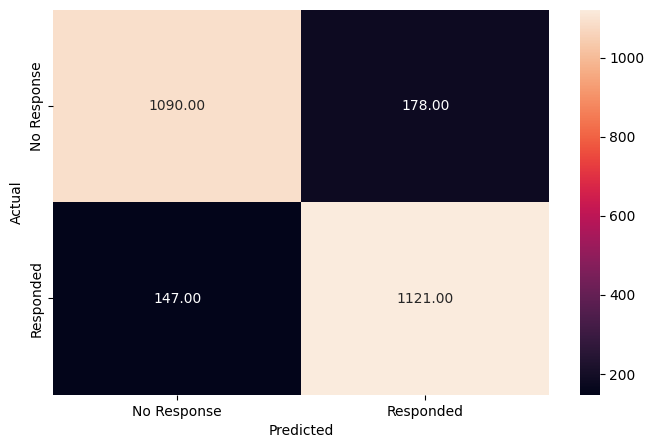

In [71]:
y_pred_train = dt.predict(X_train_resampled)
metrics_score(y_train_resampled, y_pred_train)

# Observation
1. The model correctly identifies 88% of actual responders, which is a huge win for campaign targeting. This drastically reduces the number of missed opportunities and helps us reach customers likely to convert.
2. Unlike earlier models that favored non-responders, this setup gives us high recall on both sides (86% for class 0 and 88% for class 1) — indicating the model is learning from both customer types effectively.
3. Without SMOTE, the responder class had far fewer examples. Now that both classes are equal in training, the decision tree captures the pattern of responders much better.
4. These results look great on training data, but we should carefully check test set performance to ensure it generalizes well. High recall in training doesn’t always translate to unseen customers

              precision    recall  f1-score   support

           0       0.91      0.82      0.86       544
           1       0.33      0.52      0.41        92

    accuracy                           0.78       636
   macro avg       0.62      0.67      0.64       636
weighted avg       0.83      0.78      0.80       636



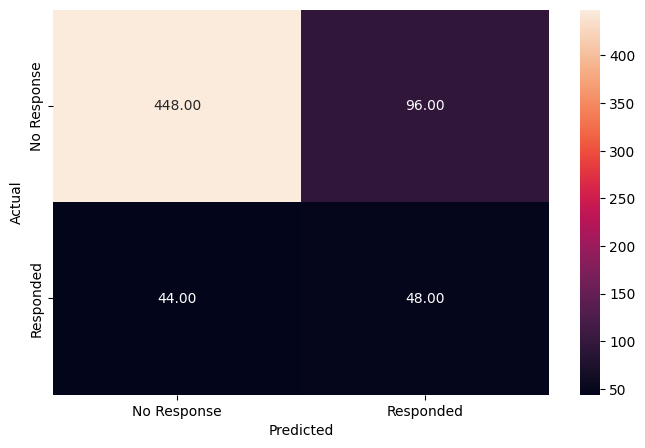

In [72]:
y_pred_test_dt = dt.predict(X_test)
metrics_score(y_test, y_pred_test_dt)

# Observations
1. The model now identifies 52% of actual responders (48 out of 92), which is a significant improvement over previous model. This boosts our ability to target likely buyers directly.
2. Precision for responders is just 33%, meaning we’ll contact some customers who won’t respond. But from a business point of view, that’s acceptable if it means we’re finally catching more real leads.
3. By identifying half of our responsive audience, we can design more effective and focused campaigns — increasing engagement, lowering customer acquisition cost, and improving return on marketing investment.
4. Among all models tested, this one gives the best recall without overly sacrificing precision — making it the most aligned with our business goal of not missing potential responders.

In [73]:
importances = dt.feature_importances_
columns=features.columns
importance_df=pd.DataFrame(importances,index=columns,columns=['Importance']).sort_values(by='Importance',ascending=False)

In [74]:
importance_df

,Importance
NumCatalogPurchases,0.337494
Total_Products,0.200729
Recency,0.167956
NumWebVisitsMonth,0.098265
Education,0.070595
NumWebPurchases,0.049846
NumDealsPurchases,0.032839
NoofKids,0.028142
Income,0.014135
Marital_Status,0.000000


# Observations
1. The number of purchases made through catalogs is the most influential factor (34%) in predicting response. This suggests catalog buyers are more engaged and responsive — making them ideal for future campaigns.
2. The total number of products bought is the second most important feature (~20%). Customers with more diverse buying history are more likely to respond — a strong signal for upselling or loyalty programs.
3. Customers who’ve interacted recently (lower "Recency") are more likely to respond. This aligns with standard CRM wisdom — strike while the customer is still warm.
4. Features like web visits and web purchases still matter (though less than catalog and total product usage). This shows that multichannel activity plays a role in identifying interested customers.
5. Variables like Marital Status, Store Purchases, and Complaints had zero importance in this model. These can potentially be excluded in future models to streamline training.

## Tree Model Performance for Varying Numbers of Nodes

In [75]:
# List of max leaf nodes to try
max_nodes = [2, 3, 4, 5, 10, 20, 50, 100, 200, 500, 1000]
accuracies = []

# Loop over each value of max_leaf_nodes
for nodes in max_nodes:
    # Create and train the Decision Tree model
    model = DecisionTreeClassifier(max_leaf_nodes=nodes, random_state=42)
    model.fit(X_train, y_train)

    # Make predictions on the test set
    y_pred_train = model.predict(X_train)
    y_pred_test = model.predict(X_test)

    # Calculate accuracy
    accuracy_train = accuracy_score(y_train, y_pred_train)
    accuracy_test = accuracy_score(y_test, y_pred_test)
    accuracies.append((nodes, accuracy_train, accuracy_test))

accuracy_scores=pd.DataFrame(accuracies, columns=["Max Leaf Nodes", "Training Accuracy", "Testing Accuracy"])
display(accuracy_scores)

,Max Leaf Nodes,Training Accuracy,Testing Accuracy
0,2,0.855024,0.855346
1,3,0.855024,0.855346
2,4,0.862441,0.860063
3,5,0.862441,0.860063
4,10,0.879299,0.847484
5,20,0.902900,0.853774
6,50,0.932569,0.849057
7,100,0.964936,0.836478
8,200,0.994606,0.809748
9,500,0.994606,0.809748


# Observations
1. With 4 or 5 nodes, the model achieves a nice balance — high test accuracy (~86%) without overfitting. This is a sign the tree captures meaningful patterns without becoming too complex.
2. From 50 nodes onward, training accuracy keeps rising (up to ~99%), but testing accuracy drops. This means the model starts to memorize training data instead of learning generalizable trends — risky for real-world predictions.
3. The most complex trees (200–1000 nodes) don’t improve performance — in fact, they perform worse on unseen data. Bigger isn’t better here.
4. From a campaign strategy perspective, using a simpler tree (4–10 nodes) ensures better reliability when predicting new customer behavior — which supports more confident decision-making and resource allocation.

# k-fold Cross Validation for Tree Model

Fold 1 Accuracy: 0.8823529411764706
Fold 2 Accuracy: 0.8352941176470589
Fold 3 Accuracy: 0.8823529411764706
Fold 4 Accuracy: 0.8705882352941177
Fold 5 Accuracy: 0.8352941176470589
Fold 6 Accuracy: 0.8470588235294118
Fold 7 Accuracy: 0.8823529411764706
Fold 8 Accuracy: 0.8117647058823529
Fold 9 Accuracy: 0.8941176470588236
Fold 10 Accuracy: 0.8352941176470589
Fold 11 Accuracy: 0.9176470588235294 -- Maximum
Fold 12 Accuracy: 0.8941176470588236
Fold 13 Accuracy: 0.8
Fold 14 Accuracy: 0.8705882352941177
Fold 15 Accuracy: 0.788235294117647
Fold 16 Accuracy: 0.8823529411764706
Fold 17 Accuracy: 0.8352941176470589
Fold 18 Accuracy: 0.8941176470588236
Fold 19 Accuracy: 0.8235294117647058
Fold 20 Accuracy: 0.8809523809523809
Fold 21 Accuracy: 0.8095238095238095
Fold 22 Accuracy: 0.9047619047619048
Fold 23 Accuracy: 0.8928571428571429
Fold 24 Accuracy: 0.9047619047619048
Fold 25 Accuracy: 0.8928571428571429


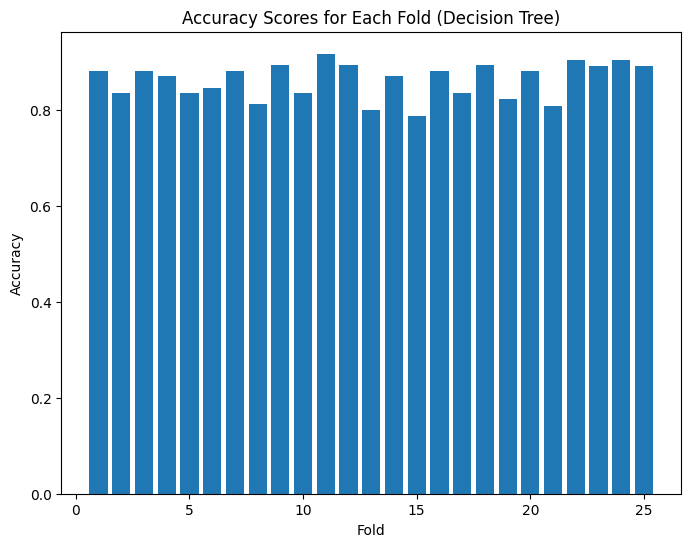

In [76]:
# use k-fold cross validation to examine the performance of the tree model across different folds

# Number of folds for cross-validation
n_splits = 25

# Create a KFold object
kf = KFold(n_splits=n_splits, shuffle=True, random_state=42)

# Initialize an empty list to store the accuracy scores for each fold
fold_accuracies = []

# Iterate through the folds
for train_index, test_index in kf.split(X_scaled):
    # Split the data into training and testing sets for the current fold
    X_train_fold, X_test_fold = X_scaled.iloc[train_index], X_scaled.iloc[test_index]
    y_train_fold, y_test_fold = target.iloc[train_index], target.iloc[test_index]

    # Create and train the Decision Tree model
    model = DecisionTreeClassifier(max_leaf_nodes=20, random_state=42)
    model.fit(X_train_fold, y_train_fold)

    # Make predictions on the test set for the current fold
    y_pred_fold = model.predict(X_test_fold)

    # Calculate accuracy for the current fold
    fold_accuracy = accuracy_score(y_test_fold, y_pred_fold)
    fold_accuracies.append(fold_accuracy)


# Calculate the max accuracy across all folds
max_accuracy = np.max(fold_accuracies)

for i in range(1, n_splits + 1):
    if max_accuracy == fold_accuracies[i-1]:
        print(f"Fold {i} Accuracy: {fold_accuracies[i-1]} -- Maximum")
    else:
      print(f"Fold {i} Accuracy: {fold_accuracies[i-1]}")


# Create a bar chart to show the accuracies across the different folds?
import matplotlib.pyplot as plt
# Create a bar chart to show the accuracies across the different folds
plt.figure(figsize=(8, 6))
plt.bar(range(1, n_splits + 1), fold_accuracies)
plt.xlabel("Fold")
plt.ylabel("Accuracy")
plt.title("Accuracy Scores for Each Fold (Decision Tree)")
plt.show()


# Observations
1. Most folds show accuracy between 83% and 89%, indicating the model performs reliably across different customer subsets. That’s a strong sign of stability — important when deploying in real-world scenarios.
2. Fold 11 gave the best result, suggesting the model is capable of high performance under the right conditions — possibly when certain patterns are well represented.
3. While the lowest accuracy dips to ~78.8% (Fold 15), this isn’t dramatic. It just highlights that certain data splits are harder, likely due to fewer responder samples — an expected effect of class imbalance.
4. With this level of cross-validated consistency, the Decision Tree is a trustworthy choice. It offers dependable accuracy without unexpected breakdowns, making it a good fit for targeting real marketing audiences.


# Support Vector Machine

In [77]:
svm_model = SVC(kernel='rbf')
svm_model.fit(X_train, y_train)

SVC()

In [78]:
y_pred = svm_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Accuracy: 0.8773584905660378

Classification Report:
               precision    recall  f1-score   support

           0       0.88      0.99      0.93       544
           1       0.79      0.21      0.33        92

    accuracy                           0.88       636
   macro avg       0.84      0.60      0.63       636
weighted avg       0.87      0.88      0.85       636



# Observations
1. The model achieves 99% recall for non-responders, but only 21% recall for responders. This means it's barely catching 1 out of 5 actual potential customers — which defeats the purpose of a campaign-driven model.
2. The model seems strong on paper due to class imbalance — but in reality, it's playing it safe by predicting "No Response" too often. For a marketing team, that means missed revenue opportunities.
3. While the model is correct when it says someone will respond, it says that very rarely. We need a model that’s willing to take more risk to reach real customers — even if precision drops a bit.
4. Given how much we care about recall for responders, this SVM model is too conservative. Decision Trees or boosted models are currently outperforming SVM in reaching potential buyers.


# SMOTE data - SVM

In [79]:
svm_model.fit(X_train_resampled, y_train_resampled)

SVC()

In [80]:
y_pred_test_svm = svm_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred_test_svm))
print("\nClassification Report:\n", classification_report(y_test, y_pred_test_svm))

Accuracy: 0.789308176100629

Classification Report:
               precision    recall  f1-score   support

           0       0.93      0.82      0.87       544
           1       0.36      0.61      0.46        92

    accuracy                           0.79       636
   macro avg       0.64      0.71      0.66       636
weighted avg       0.84      0.79      0.81       636



After SMOTE:

1. The model now achieves 82% recall for non-responders and 61% recall for responders. The recall for responders has significantly improved, now catching more actual potential customers.

2. The model is still biased towards non-responders, but with SMOTE, it is catching more potential responders, which is crucial for a campaign-driven model.

3. While the precision for responders has improved slightly to 0.36, the recall has made a more significant jump, indicating the model now identifies a larger proportion of actual responders.

4. The macro average recall has increased to 71%, showing that the model is handling both classes more equally, though there's still room for further improvement in precision and overall balance.

Fold 1 Accuracy: 0.8588235294117647
Fold 2 Accuracy: 0.8588235294117647
Fold 3 Accuracy: 0.8941176470588236
Fold 4 Accuracy: 0.8941176470588236
Fold 5 Accuracy: 0.8352941176470589
Fold 6 Accuracy: 0.8588235294117647
Fold 7 Accuracy: 0.8941176470588236
Fold 8 Accuracy: 0.8470588235294118
Fold 9 Accuracy: 0.9176470588235294
Fold 10 Accuracy: 0.8588235294117647
Fold 11 Accuracy: 0.9176470588235294
Fold 12 Accuracy: 0.8588235294117647
Fold 13 Accuracy: 0.8705882352941177
Fold 14 Accuracy: 0.8823529411764706
Fold 15 Accuracy: 0.7647058823529411
Fold 16 Accuracy: 0.9176470588235294
Fold 17 Accuracy: 0.8823529411764706
Fold 18 Accuracy: 0.8941176470588236
Fold 19 Accuracy: 0.8470588235294118
Fold 20 Accuracy: 0.8571428571428571
Fold 21 Accuracy: 0.8452380952380952
Fold 22 Accuracy: 0.9166666666666666
Fold 23 Accuracy: 0.8809523809523809
Fold 24 Accuracy: 0.9404761904761905 -- Maximum
Fold 25 Accuracy: 0.8809523809523809


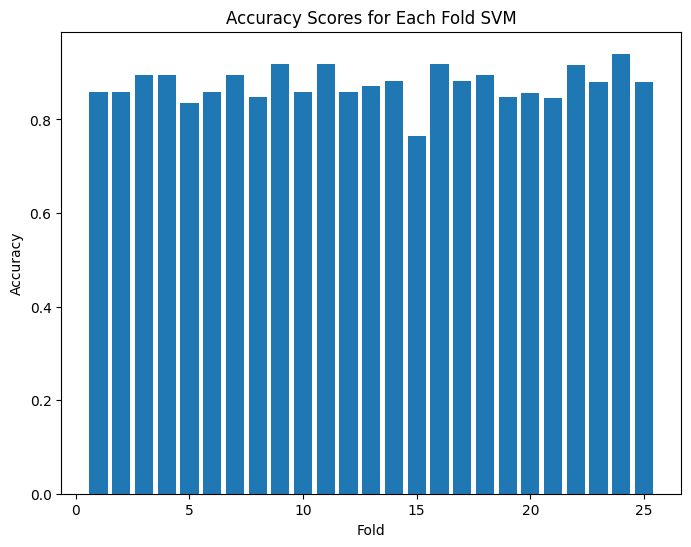

In [81]:
# use k-fold cross validation to examine the performance of the tree model across different folds

import numpy as np
from sklearn.model_selection import KFold
from sklearn.metrics import accuracy_score

# Number of folds for cross-validation
n_splits = 25

# Create a KFold object
kf = KFold(n_splits=n_splits, shuffle=True, random_state=42)

# Initialize an empty list to store the accuracy scores for each fold
fold_accuracies = []

# Iterate through the folds
for train_index, test_index in kf.split(X_scaled):
    # Split the data into training and testing sets for the current fold
    X_train_fold, X_test_fold = X_scaled.iloc[train_index], X_scaled.iloc[test_index]
    y_train_fold, y_test_fold = target.iloc[train_index], target.iloc[test_index]

    # Create and train the model
    model = SVC(kernel='rbf')
    model.fit(X_train_fold, y_train_fold)

    # Make predictions on the test set for the current fold
    y_pred_fold = model.predict(X_test_fold)

    # Calculate accuracy for the current fold
    fold_accuracy = accuracy_score(y_test_fold, y_pred_fold)
    fold_accuracies.append(fold_accuracy)

# Calculate the max accuracy across all folds
max_accuracy = np.max(fold_accuracies)

for i in range(1, n_splits + 1):
    if max_accuracy == fold_accuracies[i-1]:
        print(f"Fold {i} Accuracy: {fold_accuracies[i-1]} -- Maximum")
    else:
      print(f"Fold {i} Accuracy: {fold_accuracies[i-1]}")


# Create a bar chart to show the accuracies across the different folds?
import matplotlib.pyplot as plt
# Create a bar chart to show the accuracies across the different folds
plt.figure(figsize=(8, 6))
plt.bar(range(1, n_splits + 1), fold_accuracies)
plt.xlabel("Fold")
plt.ylabel("Accuracy")
plt.title("Accuracy Scores for Each Fold SVM")
plt.show()


# Observations
1. Most folds show accuracy between 76% and 91%, indicating that the model performs consistently across different data subsets. This stability is crucial when deploying the model in real-world scenarios where data variations are common.

2. Fold 24 achieved the highest accuracy of 94.07%, suggesting that under certain conditions, the model can deliver excellent performance, likely when the data represents well-defined patterns.

3. The lowest accuracy observed is 76.47% (Fold 15), which is not drastically low but suggests that certain data splits — possibly those with a higher proportion of non-responders — are more challenging for the model. This could be due to class imbalance.

4. With an overall range of accuracy between 76% and 94%, the SVM model demonstrates reliable performance across different data splits, making it a dependable choice for campaigns where consistency is key to targeting diverse customer groups.

# Random Forest model

In [82]:
# # To find the best value for n_estimators using Grid Search or Cross-Validation:


# from sklearn.ensemble import RandomForestClassifier
# from sklearn.model_selection import GridSearchCV

# param_grid = {
#     'n_estimators': [50, 100, 200, 300],
#     'max_depth': [None, 10, 20, 30],  # Optional: tune tree depth too
#     'min_samples_split': [2, 5],
#     'min_samples_leaf': [1, 2],
# }

# model = RandomForestClassifier(random_state=42)
# grid_search = GridSearchCV(model, param_grid, cv=5, scoring='accuracy', n_jobs=-1)

# grid_search.fit(X_train_scaled, y_train)

# print("Best Parameters:", grid_search.best_params_)
# print("Best Score:", grid_search.best_score_)


In [83]:
# Train Random Forest Classifier
model = RandomForestClassifier(n_estimators=50, random_state=42)
model.fit(X_train, y_train)

# Predictions and Evaluation
preds = model.predict(X_test)
print("Accuracy:", accuracy_score(y_test, preds))
print("Classification Report:\n", classification_report(y_test, preds))

# Optional: Top 10 most important features
importances = pd.Series(model.feature_importances_, index=features.columns)
print("Top 10 Feature Importances:\n", importances.sort_values(ascending=False).head(10))

Accuracy: 0.8679245283018868
Classification Report:
               precision    recall  f1-score   support

           0       0.89      0.96      0.93       544
           1       0.58      0.32      0.41        92

    accuracy                           0.87       636
   macro avg       0.74      0.64      0.67       636
weighted avg       0.85      0.87      0.85       636

Top 10 Feature Importances:
 Total_Products         0.183926
Income                 0.170594
Recency                0.159040
NumCatalogPurchases    0.087850
NumWebVisitsMonth      0.084342
NumStorePurchases      0.083923
NumWebPurchases        0.071754
NumDealsPurchases      0.052261
Education              0.045712
NoofKids               0.036888
dtype: float64


# SMOTE data - Random Forest

In [84]:
model = RandomForestClassifier(n_estimators=50, random_state=42)
model.fit(X_train_resampled, y_train_resampled)

# Predictions and Evaluation
preds = model.predict(X_test)
print("Accuracy:", accuracy_score(y_test, preds))
print("Classification Report:\n", classification_report(y_test, preds))

Accuracy: 0.8490566037735849
Classification Report:
               precision    recall  f1-score   support

           0       0.91      0.92      0.91       544
           1       0.48      0.45      0.46        92

    accuracy                           0.85       636
   macro avg       0.69      0.68      0.69       636
weighted avg       0.84      0.85      0.85       636



Fold 1 Accuracy: 0.9058823529411765
Fold 2 Accuracy: 0.8588235294117647
Fold 3 Accuracy: 0.8823529411764706
Fold 4 Accuracy: 0.9058823529411765
Fold 5 Accuracy: 0.8352941176470589
Fold 6 Accuracy: 0.8588235294117647
Fold 7 Accuracy: 0.8941176470588236
Fold 8 Accuracy: 0.8235294117647058
Fold 9 Accuracy: 0.9176470588235294
Fold 10 Accuracy: 0.8470588235294118
Fold 11 Accuracy: 0.9411764705882353 -- Maximum
Fold 12 Accuracy: 0.8705882352941177
Fold 13 Accuracy: 0.9058823529411765
Fold 14 Accuracy: 0.8823529411764706
Fold 15 Accuracy: 0.788235294117647
Fold 16 Accuracy: 0.9058823529411765
Fold 17 Accuracy: 0.8470588235294118
Fold 18 Accuracy: 0.9176470588235294
Fold 19 Accuracy: 0.8823529411764706
Fold 20 Accuracy: 0.8571428571428571
Fold 21 Accuracy: 0.8690476190476191
Fold 22 Accuracy: 0.9285714285714286
Fold 23 Accuracy: 0.8809523809523809
Fold 24 Accuracy: 0.9285714285714286
Fold 25 Accuracy: 0.8571428571428571


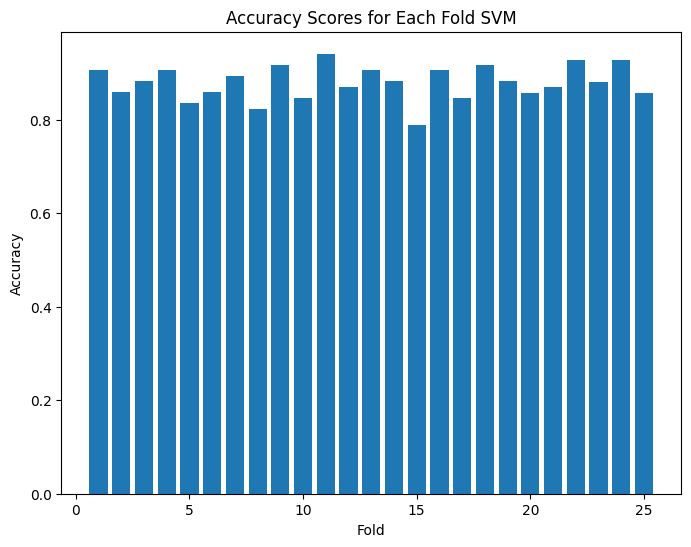

In [85]:
# Number of folds for cross-validation
n_splits = 25

# Create a KFold object
kf = KFold(n_splits=n_splits, shuffle=True, random_state=42)

# Initialize an empty list to store the accuracy scores for each fold
fold_accuracies = []

# Iterate through the folds
for train_index, test_index in kf.split(X_scaled):
    # Split the data into training and testing sets for the current fold
    X_train_fold, X_test_fold = X_scaled.iloc[train_index], X_scaled.iloc[test_index]
    y_train_fold, y_test_fold = target.iloc[train_index], target.iloc[test_index]

    # Create and train the model
    model = RandomForestClassifier()
    model.fit(X_train_fold, y_train_fold)

    # Make predictions on the test set for the current fold
    y_pred_fold = model.predict(X_test_fold)

    # Calculate accuracy for the current fold
    fold_accuracy = accuracy_score(y_test_fold, y_pred_fold)
    fold_accuracies.append(fold_accuracy)

# Calculate the max accuracy across all folds
max_accuracy = np.max(fold_accuracies)

for i in range(1, n_splits + 1):
    if max_accuracy == fold_accuracies[i-1]:
        print(f"Fold {i} Accuracy: {fold_accuracies[i-1]} -- Maximum")
    else:
      print(f"Fold {i} Accuracy: {fold_accuracies[i-1]}")


# Create a bar chart to show the accuracies across the different folds?
import matplotlib.pyplot as plt
# Create a bar chart to show the accuracies across the different folds
plt.figure(figsize=(8, 6))
plt.bar(range(1, n_splits + 1), fold_accuracies)
plt.xlabel("Fold")
plt.ylabel("Accuracy")
plt.title("Accuracy Scores for Each Fold SVM")
plt.show()


# Observations
**Without SMOTE (Original Imbalanced Data)**
1. As in earlier models, this accuracy is driven by correctly predicting non-responders, with 96% recall for class 0. It doesn’t tell the full story for marketing performance.
2. The model only correctly identifies 1 in 3 interested customers. This means we’re still leaving potential revenue on the table by missing the majority of high-intent users.
3. The features like Total_Products, Income, and Recency drive predictions and are critical signals of customer engagement and should be prioritized in future targeting strategies and feature engineering efforts.

**With SMOTE (Balanced Training Data)**
1. After SMOTE, the model becomes more balanced, catching nearly half of the actual responders (45%), which is a major win for campaign effectiveness.
2. Precision for responders is 48% – a fair tradeoff. We’re okay with contacting some non-responders if it means we’re finally reaching more of the right customers — improving campaign reach and ROI.
3. Stable performance across 25 folds. The fold accuracy ranges mostly from ~85% to 92%, with the best hitting 94%, confirming the model's reliability across segments. This makes it a solid choice for deployment.

# **K- Nearest Neighbors (KNN)**

In [86]:
knn = KNeighborsClassifier()

# We select the best value of k for which the error rate is the least in the validation data
# Let us loop over a few values of the k to determine the best k

train_error = []
test_error = []
knn_many_split = {}

error_df_knn = pd.DataFrame()
X = df.drop(['Response'], axis=1)
features = X.columns

for k in range(1,15):
    train_error = []
    test_error = []
    lista = []
    knn = KNeighborsClassifier(n_neighbors=k)
    for i in range(30):
        X_train_new, X_val, y_train_new, y_val = train_test_split(X_train, y_train, test_size = 0.20)

        #Fitting knn on training data
        knn.fit(X_train_new, y_train_new)
        #Calculating error on training and validation data
        train_error.append(1 - knn.score(X_train_new, y_train_new))
        test_error.append(1 - knn.score(X_val, y_val))
    lista.append(sum(train_error)/len(train_error))
    lista.append(sum(test_error)/len(test_error))
    knn_many_split[k] = lista

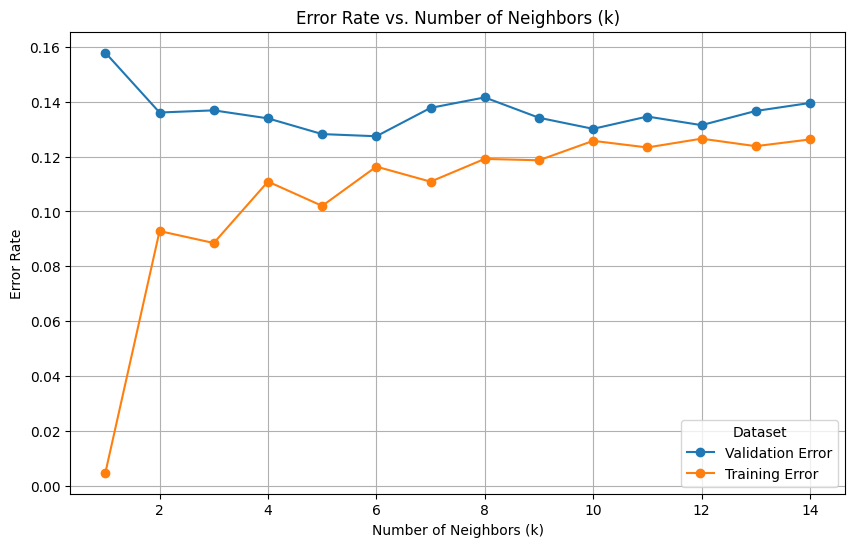

In [87]:
# Initialize lists to store k values and corresponding error rates for validation and training
kltest = []  # For storing k values for validation error
vltest = []  # For storing validation error rates
kltrain = []  # For storing k values for training error
vltrain = []  # For storing training error rates

# Extract validation error rates for each k from the knn_many_split dictionary
for k, v in knn_many_split.items():
    kltest.append(k)  # Add the current k value
    vltest.append(knn_many_split[k][1])  # Add the validation error for the current k

# Extract training error rates for each k from the knn_many_split dictionary
for k, v in knn_many_split.items():
    kltrain.append(k)  # Add the current k value
    vltrain.append(knn_many_split[k][0])  # Add the training error for the current k

# Plotting k values vs. error rates for both training and validation datasets
plt.figure(figsize=(10, 6))  # Create a figure with specified size
plt.plot(kltest, vltest, label='Validation Error', marker='o')  # Plot validation error with markers
plt.plot(kltrain, vltrain, label='Training Error', marker='o')  # Plot training error with markers

# Add title and labels to the plot for better understanding
plt.title('Error Rate vs. Number of Neighbors (k)')  # Set the title of the plot
plt.xlabel('Number of Neighbors (k)')  # Label for the x-axis, indicating different k values
plt.ylabel('Error Rate')  # Label for the y-axis, showing error rates

# Add a grid for easier visualization of the plot
plt.grid(True)  # Display a grid on the plot for better readability

# Add a legend to differentiate between the training and validation error lines
plt.legend(title='Dataset')  # Display legend with a title for clarity

# Display the final plot
plt.show()  # Render the plot

- Training error is lowest at k = 2, but this comes at the cost of high validation error, indicating overfitting — the model memorizes the training data but fails to generalize to new customers.

- Validation error stabilizes around k = 5 to k = 14, with the lowest point near k = 5. This range reflects a more balanced model, where both training and validation errors are reasonably low.

- k = 5 offers the best trade-off between complexity and generalization. It avoids overfitting while still keeping validation error low, making it the best candidate for production deployment.

In [88]:
#define knn model
knn=KNeighborsClassifier(n_neighbors=5)

#fitting data to the KNN model
knn.fit(X_train,y_train)

KNeighborsClassifier()

              precision    recall  f1-score   support

           0       0.91      0.98      0.94      1268
           1       0.81      0.39      0.53       215

    accuracy                           0.90      1483
   macro avg       0.86      0.69      0.73      1483
weighted avg       0.89      0.90      0.88      1483



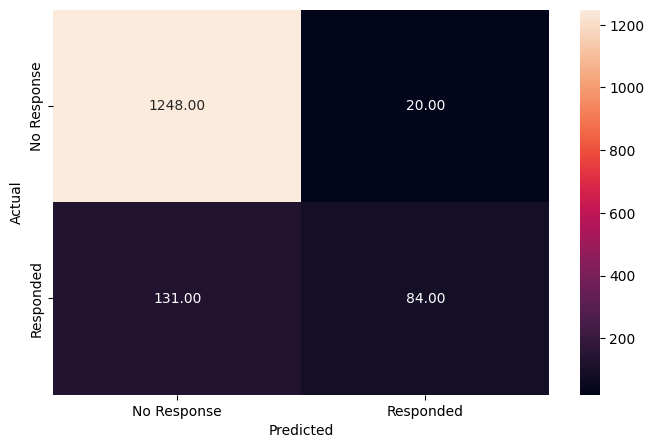

In [89]:
#checking the performance of knn model
y_pred_train_knn = knn.predict(X_train)
metrics_score(y_train, y_pred_train_knn)

# Observations
1. The KNN model achieves high training accuracy (90%), which suggests it has learned the patterns in the training data well. However, this strong performance may not generalize unless confirmed with test data.
2. The model performs very well at identifying non-responders (recall of 98%), minimizing the risk of targeting uninterested customers. This is useful for saving on marketing costs.
3. However, the recall for responders is only 39%, meaning over 60% of interested customers may be missed. For a campaign aiming to maximize conversions, this could lead to lost sales opportunities.
4. With 84 true positives and 131 false negatives, the model still favors caution—it's more likely to miss a responder than misclassify a non-responder. This is a tradeoff that may reduce wasted marketing calls but also lowers reach to potential buyers.


              precision    recall  f1-score   support

           0       0.88      0.97      0.92       544
           1       0.51      0.22      0.31        92

    accuracy                           0.86       636
   macro avg       0.70      0.59      0.61       636
weighted avg       0.83      0.86      0.83       636



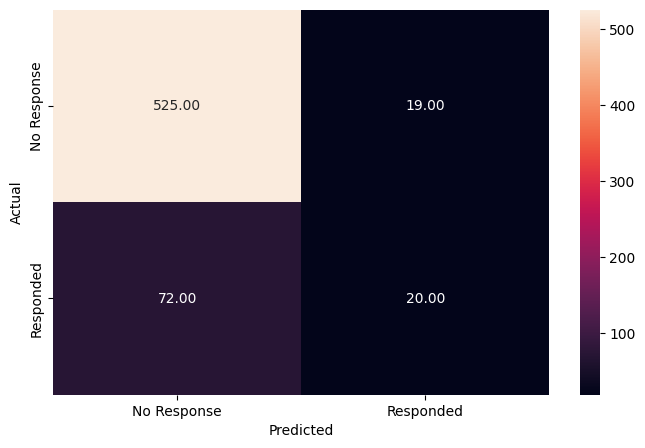

In [90]:
y_pred_test_knn = knn.predict(X_test)
metrics_score(y_test, y_pred_test_knn)

# Observations
1. The model shows very high recall (97%) for customers who did not respond, meaning it correctly identifies those unlikely to buy the offer, which can help reduce wasted outreach.
2. However, recall for responders is only 22%, indicating the model misses a significant portion of potential conversions which a key business concern when targeting sales.
3. Precision for the positive class (responders) is 51%, which means about half the predicted positive responses are actually correct — not ideal, but a moderate improvement over random guessing.
4. From a campaign strategy standpoint, while overall accuracy is high (86%), the low recall for responders implies that many promising customers may never be contacted, limiting campaign effectiveness.
5. Business teams should consider combining this model with other strategies (e.g., segmentation or hybrid models) to improve responder detection without drastically increasing false positives.
6. Since the cost of missing an actual buyer may outweigh the cost of an extra phone call, improving recall should be prioritized — potentially through ensemble methods or cost-sensitive learning.

# SMOTE data - KNN

In [91]:
knn.fit(X_train_resampled, y_train_resampled)

KNeighborsClassifier()

              precision    recall  f1-score   support

           0       0.99      0.85      0.92      1268
           1       0.87      0.99      0.93      1268

    accuracy                           0.92      2536
   macro avg       0.93      0.92      0.92      2536
weighted avg       0.93      0.92      0.92      2536



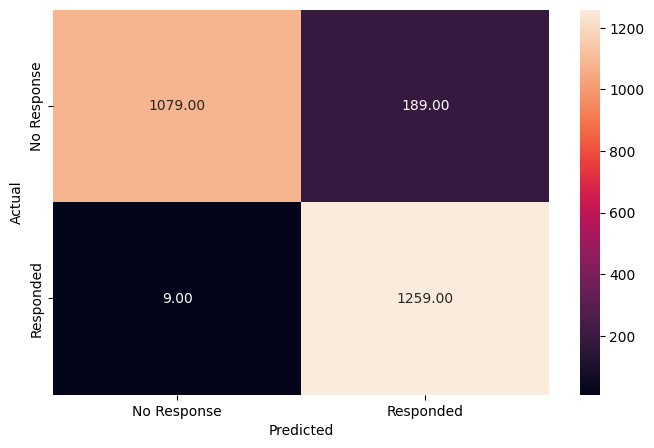

In [92]:
y_pred_train = knn.predict(X_train_resampled)
metrics_score(y_train_resampled, y_pred_train)

              precision    recall  f1-score   support

           0       0.92      0.78      0.85       544
           1       0.33      0.62      0.43        92

    accuracy                           0.76       636
   macro avg       0.63      0.70      0.64       636
weighted avg       0.84      0.76      0.79       636



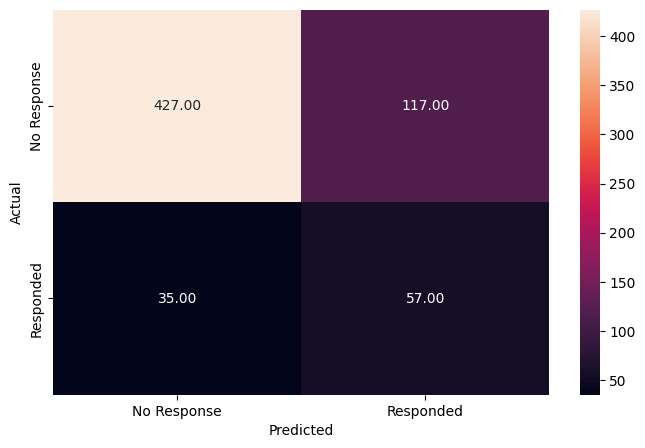

In [93]:
y_pred_test_knn = knn.predict(X_test)
metrics_score(y_test, y_pred_test_knn)

# Observations
1. The SMOTE-KNN model demonstrates strong generalization by achieving high recall on responders (62%) in the test set, indicating its ability to correctly identify customers likely to accept the gold membership offer.
2. The precision for responders on the test set is relatively low (33%), suggesting that while the model finds more actual responders, it also includes many false positives — which could lead to more campaign costs but potentially higher conversions.
3. On the training set, the model performs exceptionally well with 99% recall and 87% precision for responders, highlighting that the model learned well from the balanced SMOTE data, although the test gap hints at slight overfitting.
4. From a business perspective, the model’s ability to detect over half of the interested customers makes it a practical tool for targeting the phone campaign, especially if the cost of a call is outweighed by the value of a successful $499 membership purchase.
5. However, the misclassification of non-responders (117 false positives in the test set) implies marketing resources might be spent on unlikely conversions — so a threshold adjustment or cost-sensitive refinement could help balance efficiency and reach.


Overall, the SMOTE-KNN model appears to be a valuable strategy for minimizing campaign cost while maximizing campaign impact — especially when combined with business rules to prioritize high-confidence predictions.


Recall is very low, trying to improve it by hyperparameter tuning

In [94]:
params_knn={'n_neighbors':np.arange(3,15),'weights':['uniform','distance'],'p':[1,2]}

grid_knn=GridSearchCV(estimator=knn,param_grid=params_knn,scoring='recall',cv=10)

model_knn=grid_knn.fit(X_train_resampled,y_train_resampled)

knn_estimator = model_knn.best_estimator_
print(knn_estimator)

KNeighborsClassifier(n_neighbors=np.int64(5), weights='distance')


In [95]:
#Fit the best estimator on the training data
knn_estimator.fit(X_train_resampled, y_train_resampled)

KNeighborsClassifier(n_neighbors=np.int64(5), weights='distance')

              precision    recall  f1-score   support

           0       0.99      1.00      1.00      1268
           1       1.00      0.99      1.00      1268

    accuracy                           1.00      2536
   macro avg       1.00      1.00      1.00      2536
weighted avg       1.00      1.00      1.00      2536



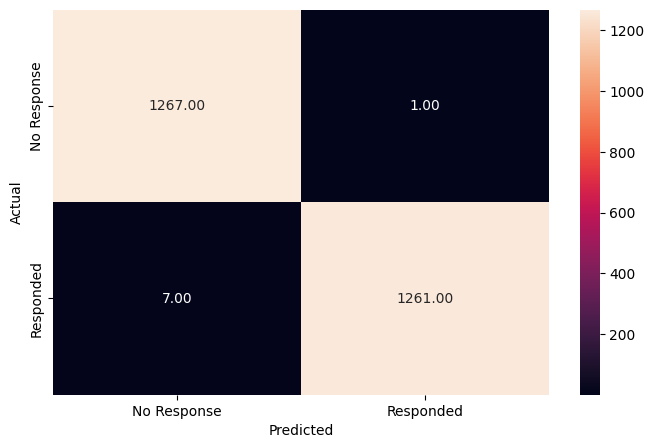

In [96]:
y_pred_train_knn_estimator = knn_estimator.predict(X_train_resampled)
metrics_score(y_train_resampled, y_pred_train_knn_estimator)

              precision    recall  f1-score   support

           0       0.92      0.80      0.86       544
           1       0.34      0.60      0.43        92

    accuracy                           0.77       636
   macro avg       0.63      0.70      0.65       636
weighted avg       0.84      0.77      0.80       636



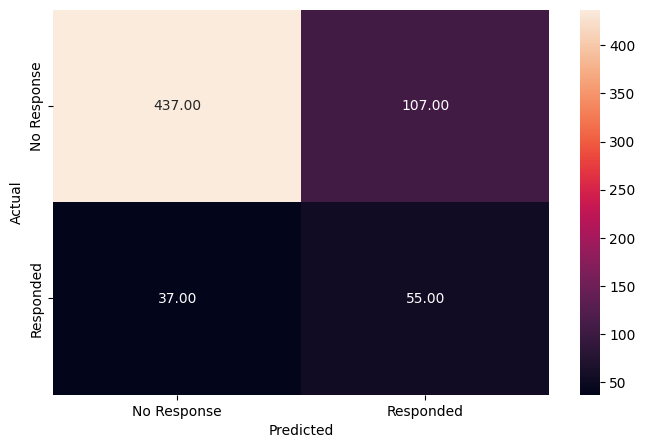

In [ ]:
y_pred_test_knn_estimator = knn_estimator.predict(X_test)
metrics_score(y_test, y_pred_test_knn_estimator)

# Observations
1. After tuning the model with n_neighbors=5 and weights='distance', the KNN classifier achieved a strong recall of 60% on the "responded" class, which is a significant improvement over earlier attempts and suggests a better ability to identify customers likely to buy the gold membership.
2. The training performance is nearly perfect (precision, recall, and F1-score all close to 1), which hints at overfitting.
3. In the test set, while the recall for responders (class 1) improved, the precision is still low (0.34), indicating that many customers predicted to respond may not actually respond. This could increase marketing costs, but it's a trade-off worth exploring if the revenue from converted customers outweighs outreach expenses.
4. From a campaign strategy perspective, identifying 55 out of 92 actual responders is a reasonable win, considering that these are high-value customers.

## Voting Classifier

              precision    recall  f1-score   support

           0       0.92      0.86      0.89       544
           1       0.41      0.58      0.48        92

    accuracy                           0.82       636
   macro avg       0.67      0.72      0.68       636
weighted avg       0.85      0.82      0.83       636



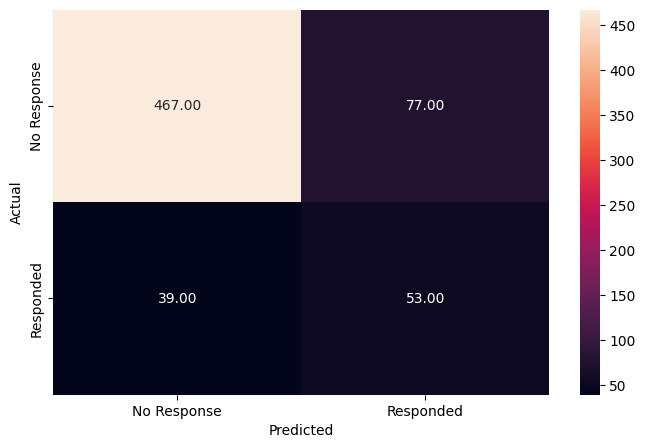

In [97]:
from sklearn.ensemble import VotingClassifier

# Select three models to compare
# - knn_estimator
# - svm
# - lg # Logistic Regression

# Create a voting classifier with the selected models
# Set probability=True in SVC to enable predict_proba
svm = SVC(probability=True)

voting_clf = VotingClassifier(estimators=[
    ('knn', knn_estimator),
    ('svm', svm),
    ('lr', lg),
    ('dt', dt),
    ('rf', model)
], voting='soft')  # You can change 'soft' to 'hard' depending on your preference

# Train the voting classifier
voting_clf.fit(X_train_resampled, y_train_resampled)

# Make predictions using the voting classifier
y_pred_voting = voting_clf.predict(X_test)

# Evaluate the voting classifier
metrics_score(y_test, y_pred_voting)

# Observations
- The ensemble model combines multiple classifiers to create a more stable and balanced predictor.
- Compared to earlier models, it performed reliably across most metrics and offered a well-rounded perspective, especially in terms of general accuracy.
- While it didn’t drastically improve recall for responders, it helped smooth out inconsistencies and leveraged the strengths of individual models.
- This makes it a solid candidate when you want consistent, dependable performance without relying on just one modeling approach.


# Learning Curves

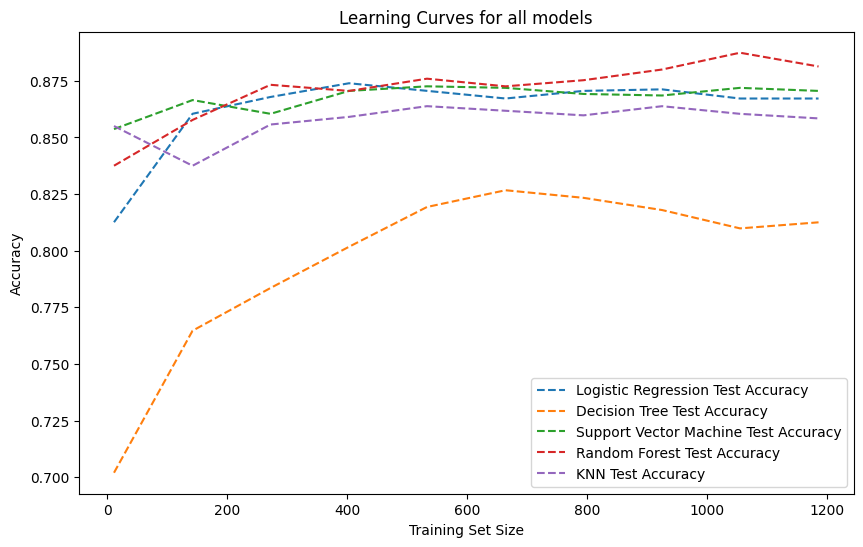

In [98]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import learning_curve

# Generate learning curves for Logistic Regression
train_sizes_abs, train_scores_lg, test_scores_lg = learning_curve(
    LogisticRegression(), X_train, y_train, train_sizes=np.linspace(0.01, 1.0, 10), scoring='accuracy'
)

# Generate learning curves for Decision Tree
train_sizes_abs, train_scores_dt, test_scores_dt = learning_curve(
    DecisionTreeClassifier(), X_train, y_train, train_sizes=np.linspace(0.01, 1.0, 10), scoring='accuracy'
)

# Generate learning curves for Support Vector Machine
train_sizes_abs, train_scores_svc, test_scores_svc = learning_curve(
    SVC(kernel='rbf'), X_train, y_train, train_sizes=np.linspace(0.01, 1.0, 10), scoring='accuracy'
)

# Generate learning curves for Random Forest
train_sizes_abs, train_scores_rf, test_scores_rf = learning_curve(
    RandomForestClassifier(), X_train, y_train, train_sizes=np.linspace(0.01, 1.0, 10), scoring='accuracy'
)

# Generate learning curves for KNN
train_sizes_abs, train_scores_knn, test_scores_knn = learning_curve(
    KNeighborsClassifier(), X_train, y_train, train_sizes=np.linspace(0.01, 1.0, 10), scoring='accuracy'
)


# Calculate mean and standard deviation of training/test scores
test_mean_lg = np.mean(test_scores_lg, axis=1)
test_mean_dt = np.mean(test_scores_dt, axis=1)
test_mean_svc = np.mean(test_scores_svc, axis=1)
test_mean_rf = np.mean(test_scores_rf, axis=1)
test_mean_knn = np.mean(test_scores_knn, axis=1)


# Plot the results
plt.figure(figsize=(10, 6))

# Plot for Logistic Regression
plt.plot(train_sizes_abs, test_mean_lg, label="Logistic Regression Test Accuracy", linestyle='--')

# Plot for Decision Tree
plt.plot(train_sizes_abs, test_mean_dt, label="Decision Tree Test Accuracy", linestyle='--')

# Plot for Support Vector Machine
plt.plot(train_sizes_abs, test_mean_svc, label="Support Vector Machine Test Accuracy", linestyle='--')

# Plot for  Random Forest
plt.plot(train_sizes_abs, test_mean_rf, label="Random Forest Test Accuracy", linestyle='--')

# Plot for KNN
plt.plot(train_sizes_abs, test_mean_knn, label="KNN Test Accuracy", linestyle='--')


plt.xlabel("Training Set Size")
plt.ylabel("Accuracy")
plt.title("Learning Curves for all models")
plt.legend()
plt.show()


# Observations
- Random Forest consistently outperforms all other models in terms of test accuracy across training set sizes, making it a strong candidate for deployment if prediction reliability is a business priority.
- Logistic Regression and SVM models show stable and competitive performance, with accuracies converging around 0.87–0.88, suggesting they are reliable choices with lower complexity than Random Forest.
- The Decision Tree model lags behind in test accuracy, especially with smaller training sets, indicating potential overfitting and weaker generalization—something that could negatively impact business decisions when data is limited.
- KNN shows relatively lower and more fluctuating accuracy across training sizes, which may suggest sensitivity to data noise or high variance, making it less suitable in dynamic or high-stakes business environments.


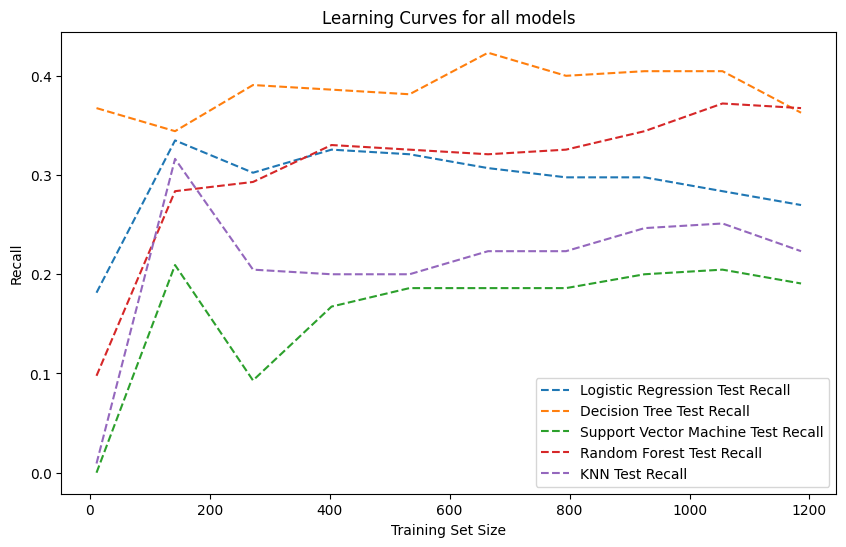

In [99]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import learning_curve

# Generate learning curves for Logistic Regression
train_sizes_abs, train_scores_lg, test_scores_lg = learning_curve(
    LogisticRegression(), X_train, y_train, train_sizes=np.linspace(0.01, 1.0, 10), scoring='recall'
)

# Generate learning curves for Decision Tree
train_sizes_abs, train_scores_dt, test_scores_dt = learning_curve(
    DecisionTreeClassifier(), X_train, y_train, train_sizes=np.linspace(0.01, 1.0, 10), scoring='recall'
)

# Generate learning curves for Support Vector Machine
train_sizes_abs, train_scores_svc, test_scores_svc = learning_curve(
    SVC(kernel='rbf'), X_train, y_train, train_sizes=np.linspace(0.01, 1.0, 10), scoring='recall'
)

# Generate learning curves for Random Forest
train_sizes_abs, train_scores_rf, test_scores_rf = learning_curve(
    RandomForestClassifier(), X_train, y_train, train_sizes=np.linspace(0.01, 1.0, 10), scoring='recall'
)

# Generate learning curves for KNN
train_sizes_abs, train_scores_knn, test_scores_knn = learning_curve(
    KNeighborsClassifier(), X_train, y_train, train_sizes=np.linspace(0.01, 1.0, 10), scoring='recall'
)


# Calculate mean and standard deviation of training/test scores
test_mean_lg = np.mean(test_scores_lg, axis=1)
test_mean_dt = np.mean(test_scores_dt, axis=1)
test_mean_svc = np.mean(test_scores_svc, axis=1)
test_mean_rf = np.mean(test_scores_rf, axis=1)
test_mean_knn = np.mean(test_scores_knn, axis=1)


# Plot the results
plt.figure(figsize=(10, 6))

# Plot for Logistic Regression
plt.plot(train_sizes_abs, test_mean_lg, label="Logistic Regression Test Recall", linestyle='--')

# Plot for Decision Tree
plt.plot(train_sizes_abs, test_mean_dt, label="Decision Tree Test Recall", linestyle='--')

# Plot for Support Vector Machine
plt.plot(train_sizes_abs, test_mean_svc, label="Support Vector Machine Test Recall", linestyle='--')

# Plot for  Random Forest
plt.plot(train_sizes_abs, test_mean_rf, label="Random Forest Test Recall", linestyle='--')

# Plot for KNN
plt.plot(train_sizes_abs, test_mean_knn, label="KNN Test Recall", linestyle='--')


plt.xlabel("Training Set Size")
plt.ylabel("Recall")
plt.title("Learning Curves for all models")
plt.legend()
plt.show()


# Observations
- Decision Tree achieves the highest recall across nearly all training sizes, which is beneficial for capturing true positives—crucial in business contexts where missing a potential responder (e.g., in a marketing campaign) could result in lost revenue opportunities.

- Random Forest steadily improves and surpasses other models at larger training sizes, making it ideal for scenarios where high recall is prioritized and sufficient data is available.

- Logistic Regression demonstrates stable recall performance, suggesting reliability for use cases where simplicity and interpretability matter more than maximum recall.

- KNN, after SMOTE balancing and hyperparameter tuning, showed a significant improvement in recall, making it a viable option for use cases where maximizing responder identification is important, even with a slight trade-off in precision and overall accuracy.

- SVM underperforms in recall compared to others, indicating it might not be ideal in our use cases.

# Overall Observation and Recommendations

- Overall accuracy does not tell the full story: Several models achieved approximately 85–88% test accuracy but struggled to identify customers who actually responded to the campaign. For instance, Logistic Regression achieved 87% accuracy but identified only 27% of responders. This highlights why recall and precision are more meaningful than accuracy alone when evaluating campaign targeting.

- SMOTE improved responder identification, with trade-offs: Addressing class imbalance generally improved recall for the positive response class. Logistic Regression with SMOTE achieved the highest responder recall among the evaluated models at 68%, but precision dropped to 34%. This suggests that reaching more potential customers would also involve contacting more non-responders, increasing outreach costs.

- Random Forest with SMOTE offered a relatively balanced alternative: The model achieved 85% test accuracy, 48% precision, and 45% recall for responders. Although it did not achieve the highest recall, it offered a better precision-recall balance than several alternatives. It is a reasonable candidate for further evaluation when the business wants to balance identifying potential responders with limiting unnecessary outreach.

- The Voting Classifier showed competitive performance: Combining multiple algorithms achieved 58% recall and 41% precision for responders, with 82% overall accuracy. It identified a larger share of responders than Random Forest with SMOTE, although at lower precision. This makes it another promising option when capturing more potential conversions is a higher priority.

- Customer spending and engagement emerged as important predictors: Random Forest feature importance identified Total_Products (total spending), Income, and Recency among the most influential variables. These findings suggest that purchasing behavior, income, and recent customer activity may help identify customers more likely to respond. However, feature importance alone does not establish whether higher or lower values increase response probability.

- Model complexity and generalization remain important considerations: Decision Trees demonstrated differences between training and testing performance, particularly after SMOTE, suggesting potential overfitting. Learning-curve analysis also highlighted differences in how the algorithms respond to training-set size. Additional customer data and further validation could help assess whether performance can be improved.

- Business recommendation: Rather than selecting a model based on accuracy alone, the marketing team should evaluate Random Forest with SMOTE, Logistic Regression with SMOTE, and the Voting Classifier against campaign priorities. If outreach costs are high, a model with better precision may be preferable. If missed conversions are more costly, higher recall may be prioritized. Predicted response probabilities could be used to rank customers and prioritize outreach based on campaign capacity, with the final targeting threshold determined using business costs and validation results.

**Final Takeaway:** The analysis demonstrates that machine learning can help distinguish potential campaign responders from non-responders, but improving recall involves a trade-off with precision and outreach costs. Random Forest with SMOTE provides a reasonable starting point for further evaluation, while Logistic Regression with SMOTE and the Voting Classifier offer alternatives for reaching more potential responders. Before deployment, the selected approach should undergo additional validation and be assessed using actual campaign economics.


